# Лабораторная работа №2

## Нейросетевой перевод на базе Hugging Face Transformers (MarianMT, NLLB)

**ФИО студента:** Ключникова Дарья Алексеевна
**Группа:** ИНФА-221
**Вариант:** 7 (предметная область: Нефтегазовая отрасль: добыча и переработка)

---

**Цель:** развернуть NMT-пайплайн, исследовать субсловную токенизацию, батчинг, условную
кросс-энтропию и cross-attention, сравнить специализированную EN→RU модель **MarianMT**
с многоязычной **NLLB**.

**Максимум: 20 баллов**

| Критерий | Состав | Баллы |
|---|---|---:|
| Работоспособность пайплайна | MarianMT — 2 · NLLB — 2 · batching/loss/attention — 2 | **6** |
| Корректность лингвистической обработки | языковые коды и токенизация — 2 · объём корпуса (120+ сегментов, 100+ терминов) — 1 · glossary QA — 2 | **5** |
| Анализ ошибок и аргументация | 5+ различий — 2 · интерпретация loss/attention — 2 · вывод — 1 | **5** |
| Оформление и воспроизводимость | результаты и графики — 1 · README — 1 · зависимости — 1 · структура — 1 | **4** |

---

### Две особенности актуальных версий библиотек

* **`attn_implementation="eager"`.** Начиная с `transformers` 4.36 при PyTorch ≥ 2.1.1
  по умолчанию подключается ускоренная реализация внимания **SDPA**, которая не обязана
  сохранять веса: в зависимости от версии `outputs.cross_attentions` окажется пустым, и
  блок 7 упадёт с `IndexError: tuple index out of range`. Загружайте модель с явным
  `attn_implementation="eager"`.
* **Предупреждение `max_new_tokens` / `max_length`.** Безобидно (приоритет у
  `max_new_tokens`), но зашумляет вывод — логирование понижается в блоке 1.

## Суть работы за пять минут (читать до запуска кода)

### Что здесь происходит, если совсем коротко

В ЛР № 1 вы собрали **ресурсы переводчика** в форматах CAT-систем: терминологическую базу `variant_<N>.tbx` и память переводов `variant_<N>.tmx` с параллельными сегментами, проверенными человеком. Сейчас те же самые файлы становятся входом: сегменты из памяти переводов прогоняются через **две нейросетевые системы машинного перевода**, терминология из TBX служит эталоном для контроля, а русская часть TMX — эталонным переводом для сравнения.

Работа отвечает на один практический вопрос: **можно ли доверить машине перевод текстов вашей предметной области с утверждённой терминологией — и что именно придётся проверять руками?**

### Четыре явления, которые вы исследуете

| Явление | Вопрос, на который отвечаем | Где в ноутбуке |
|---|---|---|
| **Субсловная токенизация** | Как модель «видит» ваши термины: целиком или обрывками? | блоки 4, 10 |
| **Батчинг** | Сколько стоит перевод по времени и как его ускорить? | блок 6 |
| **Условная кросс-энтропия** | Насколько «привычен» для модели утверждённый перевод? | блок 7 |
| **Cross-attention** | На какие слова оригинала модель смотрела, порождая каждое слово перевода? | блок 8 |

Дальше эти четыре наблюдения складываются в одно прикладное сравнение: **специализированная EN→RU модель MarianMT против многоязычной NLLB** — и в терминологический контроль по вашему глоссарию.

### Что это даёт педагогу как специалисту

Вы получаете не «кнопку перевода», а воспроизводимую процедуру: перевести учебный материал, измерить, где система систематически ошибается на терминах, и оценить объём обязательного постредактирования. Именно так выглядит подготовка локализованного учебного контента в реальной практике: машина делает черновик, человек отвечает за терминологию и смысл.

### Главный вывод, к которому ведёт работа

Беглость перевода и его правильность — **разные вещи**. Нейросеть выдаёт гладкий русский текст, в котором специальный термин может быть искажён, заменён общеупотребительным словом или передан описательно, — и всё это при безупречной грамматике. Найти такие места в переводе своего модуля и есть задача работы. Практическое следствие: терминологический контроль нельзя делегировать модели, он остаётся отдельным этапом работы редактора.

## Блок 0. Установка зависимостей

`torch` в Colab предустановлен. Ставим `transformers`, `sentencepiece` (нужен токенизатору
NLLB) и `sacremoses` (предобработка MarianMT).

In [50]:
!pip install -q "transformers>=4.40" sentencepiece sacremoses

## Блок 1. Окружение и структура каталогов

Ячейка готова — менять её не нужно. Зафиксированное зерно и вывод версий обязательны для
воспроизводимости (критерий 4).

In [51]:
from __future__ import annotations

import json
import platform
import random
import time
from pathlib import Path
from typing import Any, Dict, Iterable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

transformers.logging.set_verbosity_error()   # убирает предупреждение о max_length

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

BASE = Path("/content/lab02") if Path("/content").exists() else Path.cwd() / "lab02"
DATA = BASE / "data"
RESULTS = BASE / "results"
FIGURES = BASE / "figures"
for folder in (DATA, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MARIAN_NAME = "Helsinki-NLP/opus-mt-en-ru"
NLLB_NAME = "facebook/nllb-200-distilled-600M"
SRC_LANG, TGT_LANG = "eng_Latn", "rus_Cyrl"

MIN_SEGMENTS, MIN_TERMS = 120, 100

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

ENVIRONMENT = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "device": str(DEVICE),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "-",
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>13}: {value}")
print(f"{'base_dir':>13}: {BASE}")
if DEVICE.type != "cuda":
    print("\nВНИМАНИЕ: GPU не подключён. Runtime -> Change runtime type -> T4 GPU.")

       python: 3.13.16
        torch: 2.11.0+cu130
 transformers: 5.21.0
       device: cuda
          gpu: Tesla T4
     base_dir: /content/lab02


## Блок 2. Данные: артефакты ЛР № 1 (TBX и TMX)

**Что нужно подготовить.** Вход работы — файлы, которые вы уже сдавали в ЛР № 1:

| Файл ЛР № 1 | Обязателен | Что из него берётся |
|---|---|---|
| `variant_<N>.tmx` — память переводов | да (или CSV-замена) | параллельные сегменты: английский `<seg>` → `source`, русский `<seg>` → `reference`, `tuid` → `segment_id` |
| `variant_<N>.tbx` — терминологическая база | да (или CSV-замена) | термины: английский `<term>` → `en`, русский `<term>` → `ru` |
| `tm_segments_v<N>.csv` | резервный путь | колонки `tuid`, `source_segment`, `target_segment` |
| `glossary_smartcat_v<N>.csv` | резервный путь | колонки `Source (en)`, `Target (ru)` |

XML-файлы предпочтительнее: в них сохранены порядок сегментов, коды языков и предметная область (`prop[@type="domain"]`), а CSV-выгрузка часть этого теряет.

### Блок 2.0. Адаптер артефактов ЛР № 1

> Ячейка ниже содержит готовый адаптер: функции `tmx_to_pairs()` и `tbx_to_glossary()` разбирают XML стандартов TMX 1.4b и TBX (ISO 30042) теми же приёмами, что и ЛР № 1, а `build_lab02_inputs()` собирает три входных файла работы.

Ячейка готова — менять её не нужно. Если файлы ЛР № 1 не найдены, адаптер сообщит об этом и следующая ячейка создаст демонстрационный набор для проверки автотестов.

In [86]:
# --- как положить файлы ЛР № 1 в каталог DATA -------------------------------
# Способ 1 (Colab, вручную): выберите variant_<N>.tmx и variant_<N>.tbx
from google.colab import files
for name, content in files.upload().items():
     (DATA / name).write_bytes(content)

# Способ 2 (Google Drive): файлы переживут перезапуск среды
#from google.colab import drive
#drive.mount("/content/drive")
#import shutil, glob
#for path in glob.glob("/content/drive/MyDrive/lab01/variant_*.t*x"):
#     shutil.copy(path, DATA)

# ============================================================================
#  Блок 2.0. Адаптер: артефакты ЛР № 1 -> входные файлы ЛР № 2
#  Читает variant_<N>.tmx и variant_<N>.tbx (либо CSV-выгрузки для Smartcat)
#  и собирает три файла в DATA: segments_en.csv, glossary.csv, aligned_reference.csv
# ============================================================================
import glob
import re
import xml.etree.ElementTree as _ET

try:                                    # lxml безопаснее и быстрее, но не обязателен
    from lxml import etree as _LET

    def _parse_xml(path):
        parser = _LET.XMLParser(resolve_entities=False, load_dtd=False, no_network=True)
        return _LET.parse(str(path), parser)
except ImportError:                     # pragma: no cover
    def _parse_xml(path):
        return _ET.parse(str(path))

XML_LANG = "{http://www.w3.org/XML/1998/namespace}lang"
# пороги объёма могли быть заданы в блоке 1 или 2; если нет — берём требования работы
MIN_SEGMENTS = globals().get("MIN_SEGMENTS", 120)
MIN_TERMS = globals().get("MIN_TERMS", 100)
LAB1_DIR = DATA          # положите сюда файлы ЛР № 1 (.tmx/.tbx или CSV-выгрузки)


def _lang_of(node) -> str:
    """Код языка из xml:lang (или из lang для старых файлов), без региона."""
    raw = node.get(XML_LANG) or node.get("lang") or ""
    return raw.split("-")[0].lower()


def tmx_to_pairs(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TMX (память переводов ЛР № 1) -> таблица параллельных сегментов.

    Порядок <tu> в файле сохраняется: он задаёт порядок сегментов документа.
    Инлайновые теги TMX (ph/bpt/ept/it) игнорируются, берётся только текст.
    """
    root = _parse_xml(path).getroot()
    rows = []
    for order, tu in enumerate(root.iter("tu"), start=1):
        by_lang = {}
        for tuv in tu.findall("tuv"):
            seg = tuv.find("seg")
            if seg is None:
                continue
            text = re.sub(r"\s+", " ", "".join(seg.itertext())).strip()
            if text:
                by_lang[_lang_of(tuv)] = text
        if src_lang in by_lang and tgt_lang in by_lang:
            domain_node = tu.find("prop[@type='domain']")
            rows.append({"segment_id": f"s{order:03d}",
                         "tuid": tu.get("tuid", str(order)),
                         "source": by_lang[src_lang],
                         "reference": by_lang[tgt_lang],
                         "domain": (domain_node.text or "").strip()
                                   if domain_node is not None else ""})
    return pd.DataFrame(rows, columns=["segment_id", "tuid", "source", "reference", "domain"])


def tbx_to_glossary(path, src_lang: str = "en", tgt_lang: str = "ru") -> pd.DataFrame:
    """TBX (терминологическая база ЛР № 1) -> таблица терминов en/ru.

    Учитываются оба способа записи термина: <tig><term> и <ntig><termGrp><term>,
    поэтому используется поиск по всем потомкам langSet.
    """
    root = _parse_xml(path).getroot()
    rows = []
    for entry in root.iter("termEntry"):
        by_lang = {}
        for lang_set in entry.findall("langSet"):
            terms = [t.text.strip() for t in lang_set.iter("term") if (t.text or "").strip()]
            if terms:
                by_lang[_lang_of(lang_set)] = terms[0]
        if src_lang in by_lang and tgt_lang in by_lang:
            rows.append({"en": by_lang[src_lang], "ru": by_lang[tgt_lang],
                         "entry_id": entry.get("id", "")})
    return pd.DataFrame(rows, columns=["en", "ru", "entry_id"])


def _first(pattern: str):
    """Первый файл, подходящий под шаблон (ищем и в LAB1_DIR, и в текущем каталоге)."""
    found = sorted(glob.glob(str(LAB1_DIR / pattern))) + sorted(glob.glob(pattern))
    return Path(found[0]) if found else None


def build_lab02_inputs(lab1_dir=None, src_lang: str = "en", tgt_lang: str = "ru") -> dict:
    """Собрать входные файлы ЛР № 2 из артефактов ЛР № 1.

    Приоритет источников:
      1) variant_*.tmx + variant_*.tbx  — основной путь (форматы CAT-систем);
      2) tm_segments_v*.csv + glossary_smartcat_v*.csv — выгрузки для Smartcat
         (колонки tuid/source_segment/target_segment и 'Source (en)'/'Target (ru)').

    Returns:
        Словарь с числом сегментов и терминов и именами использованных источников.
    """
    global LAB1_DIR
    if lab1_dir is not None:
        LAB1_DIR = Path(lab1_dir)

    used = {}
    tmx, tbx = _first("*.tmx"), _first("*.tbx")

    if tmx is not None:
        pairs = tmx_to_pairs(tmx, src_lang, tgt_lang)
        used["segments"] = tmx.name
    else:
        tm_csv = _first("tm_segments_v*.csv") or _first("tm_segments*.csv")
        if tm_csv is None:
            raise FileNotFoundError(
                "Не найдены ни variant_*.tmx, ни tm_segments_v*.csv. "
                "Положите артефакты ЛР № 1 в каталог DATA (см. инструкцию выше).")
        frame = pd.read_csv(tm_csv, encoding="utf-8-sig")
        pairs = pd.DataFrame({
            "segment_id": [f"s{i:03d}" for i in range(1, len(frame) + 1)],
            "tuid": frame.get("tuid", pd.Series(range(1, len(frame) + 1))).astype(str),
            "source": frame["source_segment"].astype(str).str.strip(),
            "reference": frame["target_segment"].astype(str).str.strip(),
            "domain": frame.get("domain", "")})
        used["segments"] = tm_csv.name

    if tbx is not None:
        terms = tbx_to_glossary(tbx, src_lang, tgt_lang)
        used["glossary"] = tbx.name
    else:
        gl_csv = _first("glossary_smartcat_v*.csv") or _first("glossary_smartcat*.csv")
        if gl_csv is None:
            raise FileNotFoundError(
                "Не найдены ни variant_*.tbx, ни glossary_smartcat_v*.csv.")
        frame = pd.read_csv(gl_csv, encoding="utf-8-sig")
        cols = {c.lower().strip(): c for c in frame.columns}
        en_col = cols.get("source (en)") or cols.get("en") or list(frame.columns)[0]
        ru_col = cols.get("target (ru)") or cols.get("ru") or list(frame.columns)[1]
        terms = pd.DataFrame({"en": frame[en_col].astype(str).str.strip(),
                              "ru": frame[ru_col].astype(str).str.strip(),
                              "entry_id": ""})
        used["glossary"] = gl_csv.name

    # чистка: пустые строки и дубликаты из ТМ и глоссария не нужны
    pairs = (pairs[(pairs["source"].str.len() > 0) & (pairs["reference"].str.len() > 0)]
             .drop_duplicates(subset=["source"]).reset_index(drop=True))
    pairs["segment_id"] = [f"s{i:03d}" for i in range(1, len(pairs) + 1)]
    terms = (terms[(terms["en"].str.len() > 0) & (terms["ru"].str.len() > 0)]
             .drop_duplicates(subset=["en"]).reset_index(drop=True))

    pairs[["segment_id", "source"]].to_csv(DATA / "segments_en.csv",
                                           index=False, encoding="utf-8")
    pairs[["segment_id", "source", "reference"]].to_csv(DATA / "aligned_reference.csv",
                                                        index=False, encoding="utf-8")
    terms[["en", "ru"]].to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

    domains = [d for d in pairs.get("domain", pd.Series(dtype=str)).fillna("").unique() if d]
    return {"segments": len(pairs), "terms": len(terms), "sources": used,
            "domain": domains[0] if domains else ""}


# --- запуск адаптера --------------------------------------------------------
try:
    info = build_lab02_inputs()
    print("Артефакты ЛР № 1 преобразованы во входные файлы ЛР № 2")
    print(f"  источник сегментов : {info['sources']['segments']}")
    print(f"  источник глоссария : {info['sources']['glossary']}")
    print(f"  сегментов          : {info['segments']}"
          f"   (минимум для сдачи: {MIN_SEGMENTS})")
    print(f"  терминов           : {info['terms']}"
          f"   (минимум для сдачи: {MIN_TERMS})")
    if info["domain"]:
        print(f"  предметная область : {info['domain']} (из вашей ЛР № 1)")
    if info["segments"] < MIN_SEGMENTS or info["terms"] < MIN_TERMS:
        print("\nОбъём меньше минимума. Расширьте списки PARALLEL_CORPUS и TERMS "
              "в своём ноутбуке ЛР № 1, перегенерируйте variant_<N>.tmx и "
              "variant_<N>.tbx и повторите загрузку: код ЛР № 1 при этом не меняется.")
except FileNotFoundError as error:
    print("Адаптер пропущен:", error)
    print("Дальше будет использован демонстрационный набор — сдавать работу на нём нельзя.")

Saving variant_7.tbx to variant_7 (2).tbx
Saving variant_7.tmx to variant_7 (2).tmx
Артефакты ЛР № 1 преобразованы во входные файлы ЛР № 2
  источник сегментов : variant_7 (1).tmx
  источник глоссария : variant_7 (1).tbx
  сегментов          : 120   (минимум для сдачи: 120)
  терминов           : 100   (минимум для сдачи: 100)
  предметная область : Нефтегазовая отрасль: добыча и переработка (из вашей ЛР № 1)


In [87]:
# --- Способ 1: загрузка файлов с компьютера ---------------------------------
try:
    from google.colab import files

    print("Диалог нужен, только если блок 2.0 не нашёл артефакты ЛР № 1: "
          "выберите variant_<N>.tmx и variant_<N>.tbx либо готовые CSV "
          "(или закройте диалог, чтобы использовать демо-данные)")
    uploaded = files.upload()
    for name, content in uploaded.items():
        (DATA / name).write_bytes(content)
except Exception as error:  # noqa: BLE001 - вне Colab или диалог закрыт
    print("Загрузка пропущена:", error.__class__.__name__)

# --- Способ 2: Google Drive ------------------------------------------------
#from google.colab import drive
#drive.mount("/content/drive")
#import shutil
#for name in ("segments_en.csv", "glossary.csv", "aligned_reference.csv"):
#     shutil.copy(f"/content/drive/MyDrive/lab01/{name}", DATA / name)

# --- Демо-набор на случай отсутствия файлов --------------------------------
# Четыре пары и четыре термина из варианта 7 ЛР № 1 (Нефтегазовая отрасль).
# Нужны ТОЛЬКО для проверки автотестов.
DEMO_PARALLEL = [
    ("Sedimentary rocks generated as a result of organic and inorganic matter settling on bottoms of water basins.",
     "Осадочные породы образовались в результате осаждения органических и неорганических веществ на дне водных бассейнов."),
    ("A marginal well is usually kept in production only when operating costs are reduced to the minimum.",
     "Низкорентабельную скважину обычно продолжают эксплуатировать только при снижении эксплуатационных расходов до минимума."),
    ("The blowout preventer must be installed on the casing head before drilling.",
     "Противовыбросовый превентор должен быть установлен на колонной головке перед бурением."),
    ("The desalter removes salts and water from crude oil before refining.",
     "Обессоливатель удаляет соли и воду из сырой нефти перед переработкой."),
]
DEMO_GLOSSARY = [("sedimentary rocks", "осадочные породы"),
                 ("marginal well", "низкорентабельная скважина"),
                 ("blowout preventer", "противовыбросовый превентор"),
                 ("desalter", "обессоливающая установка")]

if not (DATA / "segments_en.csv").exists():
    print("\nФайлы ЛР № 1 не найдены — создаётся демонстрационный набор.")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src}
                  for i, (src, _) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "segments_en.csv", index=False, encoding="utf-8")
    pd.DataFrame([{"segment_id": f"s{i:03d}", "source": src, "reference": ref}
                  for i, (src, ref) in enumerate(DEMO_PARALLEL, 1)]
                 ).to_csv(DATA / "aligned_reference.csv", index=False, encoding="utf-8")
    pd.DataFrame(DEMO_GLOSSARY, columns=["en", "ru"]
                 ).to_csv(DATA / "glossary.csv", index=False, encoding="utf-8")

segments_df = pd.read_csv(DATA / "segments_en.csv")
glossary_df = pd.read_csv(DATA / "glossary.csv")
aligned_df = pd.read_csv(DATA / "aligned_reference.csv")

# --- проверка структуры (обязательна) --------------------------------------
assert {"segment_id", "source"} <= set(segments_df.columns), "segments_en.csv: не те колонки"
assert {"en", "ru"} <= set(glossary_df.columns), "glossary.csv: нужны колонки en и ru"
assert {"segment_id", "source", "reference"} <= set(aligned_df.columns), \
    "aligned_reference.csv: нужны колонки segment_id, source, reference"
assert len(segments_df) == len(aligned_df), \
    "segments_en.csv и aligned_reference.csv должны содержать одинаковые сегменты"


def dataset_ready(segments: pd.DataFrame, glossary: pd.DataFrame) -> bool:
    """Проверить готовность корпуса к сдаче и напечатать отчёт."""
    checks = [
        ("сегментов", len(segments), MIN_SEGMENTS),
        ("терминов", len(glossary), MIN_TERMS),
    ]
    ready = True
    for label, actual, required in checks:
        status = "ГОТОВО" if actual >= required else "НЕДОСТАТОЧНО"
        ready &= actual >= required
        print(f"  {label:<10} {actual:>4} / {required:<4} {status}")
    return ready


print(f"\nПроверка объёма корпуса:")
READY = dataset_ready(segments_df, glossary_df)
print("\nСтатус:", "корпус соответствует требованиям"
      if READY else "работа на этих данных к сдаче НЕ принимается")
print(f"Средняя длина сегмента: {segments_df['source'].str.split().str.len().mean():.1f} слов")
segments_df.head()

Диалог нужен, только если блок 2.0 не нашёл артефакты ЛР № 1: выберите variant_<N>.tmx и variant_<N>.tbx либо готовые CSV (или закройте диалог, чтобы использовать демо-данные)



Проверка объёма корпуса:
  сегментов   120 / 120  ГОТОВО
  терминов    100 / 100  ГОТОВО

Статус: корпус соответствует требованиям
Средняя длина сегмента: 14.9 слов


,segment_id,source
0,s001,Sedimentary rocks generated as a result of org...
1,s002,Seismic exploration goal is to obtain informat...
2,s003,"Rocks saturated with oil or gas, have lower de..."
3,s004,Field exploration stage includes implementatio...
4,s005,The inorganic theory assumes that carbon and h...


## Блок 3. Загрузка моделей (шаги 1–2, 8)

**Зачем этот шаг.** Мы поднимаем первую из двух систем перевода — специализированную EN→RU модель проекта OPUS-MT. Всё, что дальше считается по MarianMT (токенизация, время, loss, внимание), опирается на корректно загруженную модель.

**Что делает код ниже.** Скачивает веса и токенизатор с Hugging Face Hub, переносит модель на GPU, переводит её в режим инференса и печатает паспорт модели: класс токенизатора, размер словаря, число параметров, реализацию внимания.

**Три момента, которые нельзя пропустить.**

* `.eval()` отключает dropout. Без него один и тот же вход даёт разные результаты, и требование воспроизводимости нарушается.
* `attn_implementation="eager"` включает реализацию внимания, которая **возвращает веса**. Значение по умолчанию (SDPA, начиная с `transformers` 4.36 при PyTorch ≥ 2.1.1) этого не гарантирует, и блок 8 получит пустой `cross_attentions`. Старые версии библиотеки аргумента не знают — предусмотрен запасной путь через `try/except`.
* `torch.no_grad()` при инференсе (используется дальше) отключает построение графа вычислений: память не расходуется на градиенты.

**На что смотреть в выводе.** Поле `_attn_implementation` должно показывать `eager`; устройство — `cuda` при подключённом T4; размер словаря 62 518 — это число понадобится при сравнении с NLLB в блоке 10.

### Вторая модель — NLLB

**Теория в одном абзаце.** У многоязычной модели направление перевода задаётся не выбором модели, а **кодами языков** по схеме FLORES-200: `src_lang="eng_Latn"` для токенизатора и `forced_bos_token_id` для генерации. Технически это означает, что декодер обязан начать вывод со специального токена целевого языка; если его не задать, язык результата не определён. Слово *distilled* в названии говорит, что модель обучена воспроизводить поведение более крупной NLLB-200 — так сохраняется значительная часть качества при кратно меньших ресурсах.

**На что смотреть в выводе.** Результат контрольного эксперимента: с кодом `rus_Cyrl` перевод русский, без кода — в эталонном прогоне модель выдала испанский. Это самая частая ошибка при работе с многоязычными моделями, и увидеть её лучше на управляемом примере, чем в сданной работе.

In [54]:
def load_seq2seq(model_name: str, device: torch.device,
                 eager_attention: bool = True,
                 **tokenizer_kwargs: Any) -> Tuple[Any, Any]:
    """Загрузить токенизатор и модель seq2seq и перевести модель в режим инференса.

    Args:
        model_name: идентификатор модели на Hugging Face Hub.
        device: устройство, на которое переносится модель.
        eager_attention: загрузить модель с ``attn_implementation="eager"``; необходимо,
            чтобы ``output_attentions=True`` возвращал веса внимания.
        **tokenizer_kwargs: дополнительные параметры токенизатора (например, ``src_lang``).

    Returns:
        Кортеж ``(tokenizer, model)``.
    """
    tokenizer = AutoTokenizer.from_pretrained(model_name, **tokenizer_kwargs)
    try:
        model = AutoModelForSeq2SeqLM.from_pretrained(
            model_name,
            **({"attn_implementation": "eager"} if eager_attention else {}),
        )
    except (TypeError, ValueError):  # Совместимость со старыми версиями transformers, в которых этот аргумент отсутствует
        model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
    model = model.to(device)
    model.eval()
    return tokenizer, model

start = time.perf_counter()
marian_tokenizer, marian_model = load_seq2seq(MARIAN_NAME, DEVICE)
print(f"MarianMT загружена за {time.perf_counter() - start:.1f} с")
print(f"Параметров: {marian_model.num_parameters() / 1e6:.1f} млн")
print(f"Размер словаря: {marian_tokenizer.vocab_size}")
print(f"Класс токенизатора: {type(marian_tokenizer).__name__}")
print(f"Реализация внимания: {getattr(marian_model.config, '_attn_implementation', 'n/a')}")
print(f"Режим обучения (должен быть False): {marian_model.training}")

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

MarianMT загружена за 2.3 с
Параметров: 76.7 млн
Размер словаря: 62518
Класс токенизатора: MarianTokenizer
Реализация внимания: eager
Режим обучения (должен быть False): False


## Блок 4. Перевод сегментов (шаги 4–5, 9)

**Зачем этот шаг.** Первый содержательный результат: прежде чем гонять весь корпус, нужно убедиться, что пайплайн работает, и посмотреть на качество перевода вблизи — на одном сегменте, где видно каждое слово.

**Что делает код ниже.** Токенизирует сегмент, вызывает `generate()` с лучевым поиском и декодирует результат обратно в текст. Генерация выполняется под `torch.no_grad()` и без случайной выборки, поэтому результат воспроизводим.

**На что смотреть в выводе.** Сравните перевод с эталоном ЛР № 1 по двум осям отдельно: **беглость** (грамматика, согласование, порядок слов) и **точность терминов**. Именно здесь обычно обнаруживается главный сюжет работы: текст читается безупречно, а термин искажён. Запишите такой случай — он войдёт в анализ различий (блок 14).

In [55]:
def translate_batch(texts: Sequence[str], tokenizer: Any, model: Any,
                    device: torch.device, num_beams: int = 4,
                    max_new_tokens: int = 128,
                    forced_bos_token_id: Optional[int] = None) -> List[str]:
    """Перевести список сегментов одним пакетом.

    Args:
        texts: сегменты исходного языка.
        tokenizer: токенизатор модели.
        model: модель seq2seq в режиме ``eval``.
        device: устройство инференса.
        num_beams: ширина луча при декодировании.
        max_new_tokens: ограничение длины порождаемой последовательности.
        forced_bos_token_id: принудительный первый токен (код целевого языка для NLLB).

    Returns:
        Список переводов в порядке входных сегментов.
    """
    batch = tokenizer(list(texts), return_tensors="pt",
                      padding=True, truncation=True).to(device)
    generate_kwargs: Dict[str, Any] = {
        "num_beams": num_beams,
        "max_new_tokens": max_new_tokens,
    }
    if forced_bos_token_id is not None:
        generate_kwargs["forced_bos_token_id"] = forced_bos_token_id

    with torch.no_grad():
        generated = model.generate(**batch, **generate_kwargs)
    return tokenizer.batch_decode(generated, skip_special_tokens=True)

# Для демонстрации используется первый сегмент памяти переводов ЛР № 1
DEMO_ROW = 0
demo_id = aligned_df.loc[DEMO_ROW, "segment_id"]
demo = aligned_df.loc[DEMO_ROW, "source"]
demo_reference = aligned_df.loc[DEMO_ROW, "reference"]
demo_marian = translate_batch([demo], marian_tokenizer, marian_model, DEVICE)[0]
print("Сегмент:", demo_id)
print("EN    :", demo)
print("Marian:", demo_marian)
print("Эталон:", demo_reference)

def timed_sequential(texts: Sequence[str], tokenizer: Any, model: Any,
                     device: torch.device, **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты по одному и измерить суммарное время."""
    start_time = time.perf_counter()
    outputs = [translate_batch([text], tokenizer, model, device, **kwargs)[0]
               for text in texts]
    return outputs, time.perf_counter() - start_time


def timed_batched(texts: Sequence[str], tokenizer: Any, model: Any,
                  device: torch.device, batch_size: int = 8,
                  **kwargs: Any) -> Tuple[List[str], float]:
    """Перевести сегменты пачками по ``batch_size`` и измерить суммарное время."""
    start_time = time.perf_counter()
    outputs: List[str] = []
    for offset in range(0, len(texts), batch_size):
        outputs.extend(translate_batch(texts[offset:offset + batch_size],
                                       tokenizer, model, device, **kwargs))
    return outputs, time.perf_counter() - start_time

Сегмент: s001
EN    : Sedimentary rocks generated as a result of organic and inorganic matter settling on bottoms of water basins and surface of continents.
Marian: Осадочные породы, образующиеся в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.
Эталон: Осадочные породы образовались в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности материков.


## Блок 5. Субсловная токенизация (шаги 3, 10)

**Зачем этот шаг.** Прежде чем разбираться, почему модель путает термины, нужно увидеть, в каком виде эти термины вообще до неё доходят. Модель не работает со словами: она работает с подсловными единицами из фиксированного словаря.

**Что делает код ниже.** Прогоняет каждый термин глоссария ЛР № 1 через токенизатор MarianMT (без специальных токенов) и сохраняет таблицу «термин → список токенов → их количество» в `results/tokenization_10_terms.csv`.

**На что смотреть в выводе.** Сколько терминов уложились в один-два токена (модель «знает» их целиком) и какие дробятся на четыре и более (модель собирает их из фрагментов). Составьте мысленный список кандидатов на терминологические ошибки — в блоке 12 вы проверите, совпал ли он с фактическими нарушениями глоссария.

In [56]:
def tokenize_terms(terms: Sequence[str], tokenizer: Any,
                   label: str) -> pd.DataFrame:
    """Разобрать список терминов токенизатором модели.

    Args:
        terms: термины на исходном языке.
        tokenizer: токенизатор Hugging Face.
        label: имя модели для колонки ``model``.

    Returns:
        ``pd.DataFrame`` с колонками ``model``, ``term``, ``n_words``, ``n_tokens``,
        ``tokens``, ``is_word_level`` (термин не распался на подслова).
    """
    rows: List[Dict[str, Any]] = []
    for term in terms:
        ids = tokenizer(term, add_special_tokens=False)["input_ids"]
        tokens = tokenizer.convert_ids_to_tokens(ids)
        rows.append({
            "model": label,
            "term": term,
            "n_words": len(term.split()),
            "n_tokens": len(tokens),
            "tokens": " ".join(tokens),
            "is_word_level": len(tokens) == len(term.split()),
        })
    return pd.DataFrame(rows)

terms = glossary_df["en"].tolist()
marian_tokens_df = tokenize_terms(terms, marian_tokenizer, "MarianMT")
marian_tokens_df.to_csv(RESULTS / "tokenization_10_terms.csv",
                        index=False, encoding="utf-8-sig")

print(f"Разобрано терминов: {len(marian_tokens_df)}")
print(f"Совпадают со словами: {int(marian_tokens_df['is_word_level'].sum())} "
      f"из {len(marian_tokens_df)}")
print(f"Среднее число токенов на термин: {marian_tokens_df['n_tokens'].mean():.2f}")
print(f"Максимальное дробление: "
      f"{marian_tokens_df.loc[marian_tokens_df['n_tokens'].idxmax(), 'term']} "
      f"({marian_tokens_df['n_tokens'].max()} токенов)\n")
for row in marian_tokens_df.head(8).itertuples(index=False):
    print(f"{row.term:<26} => {row.tokens}")

Разобрано терминов: 100
Совпадают со словами: 43 из 100
Среднее число токенов на термин: 2.64
Максимальное дробление: blowout preventer (BOP) (8 токенов)

amplitude                  => ▁am pl itude
aquifer                    => ▁aquifer
appraisal                  => ▁appraisal
air drilling               => ▁air ▁drilling
asphaltenes                => ▁as ph al ten es
asphalt                    => ▁as pha lt
bit                        => ▁bit
blowout                    => ▁blow out


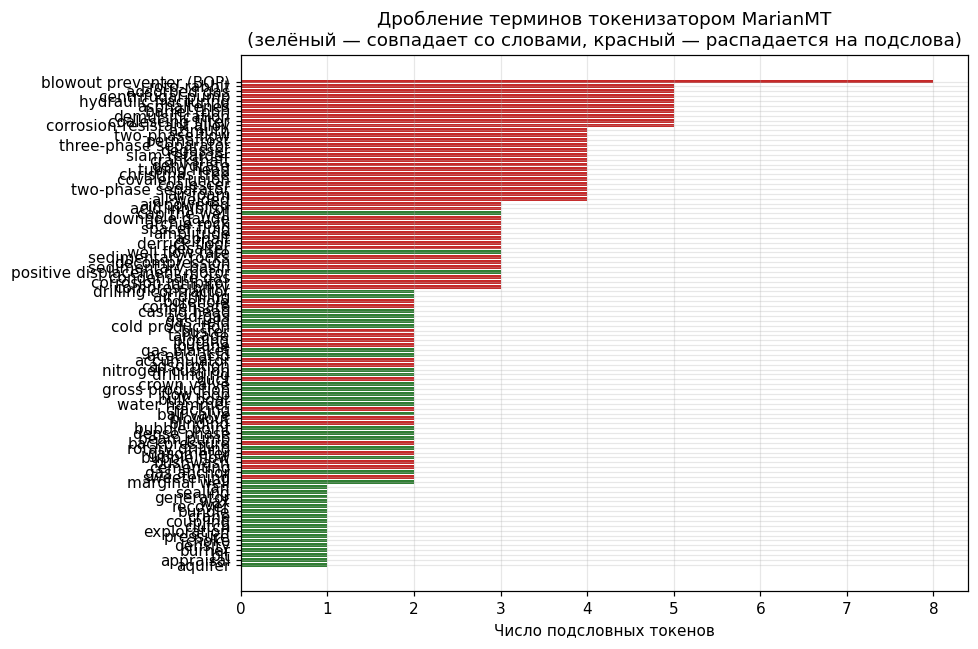

In [57]:
plot_df = marian_tokens_df.sort_values("n_tokens", ascending=True)
colors = ["#2e7d32" if flag else "#c62828" for flag in plot_df["is_word_level"]]

figure, axes = plt.subplots(figsize=(9, 6))
axes.barh(plot_df["term"], plot_df["n_tokens"], color=colors)
axes.set_xlabel("Число подсловных токенов")
axes.set_title("Дробление терминов токенизатором MarianMT\n"
               "(зелёный — совпадает со словами, красный — распадается на подслова)")
figure.tight_layout()
figure.savefig(FIGURES / "tokenization_marian.png")
plt.show()

## Блок 6. Условная кросс-энтропия (шаг 6)

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T}\log P\left(y_t \mid y_{1:t-1}, x\right)$$

**Зачем этот шаг.** Нам нужен числовой индикатор, который покажет, где утверждённый в ЛР № 1 перевод расходится с тем, что модель считает «естественным». Это ранний сигнал терминологического конфликта — до всякого ручного разбора.

**Что делает код ниже.** Для каждой пары «оригинал — эталон» модель получает **готовую** целевую строку и оценивает вероятность каждого её токена при условии правильного префикса (режим teacher forcing, то же вычисление, что и при обучении). То же самое считается для собственного вывода модели. Результат — `results/loss_5_pairs.csv`.

**Как читать число.** Меньше — строка более вероятна для этой модели. Удобная интерпретация — перплексия $e^{\mathcal{L}}$: «из скольких равновероятных вариантов модель фактически выбирала». Значение нормировано на длину, паддинг из усреднения исключён.

**Чего это число не означает.** Это **не метрика качества перевода** и не основание сказать, что один перевод лучше другого. Loss несопоставим между MarianMT и NLLB: у них разные словари, разное число токенов на ту же строку и разное пространство событий. Метрики качества (BLEU, chrF, COMET) появятся в следующей работе курса.

**На что смотреть в выводе.** Соотношение `loss_reference` и `loss_own_output` (второе почти всегда ниже — модель «увереннее» в том, что породила сама) и сегменты с наибольшим `loss_reference`: проверьте, не в них ли стоят термины вашего глоссария.

In [58]:
def sequence_cross_entropy(source: str, target: str, tokenizer: Any,
                           model: Any, device: torch.device) -> float:
    """Вычислить условную кросс-энтропию целевой строки при данном источнике.

    Args:
        source: сегмент на исходном языке.
        target: целевая строка (эталон или гипотеза модели).
        tokenizer: токенизатор модели.
        model: модель seq2seq.
        device: устройство вычислений.

    Returns:
        Средний ``-log P`` на токен; чем меньше, тем вероятнее строка для данной модели.
    """
    batch = tokenizer(source, text_target=target, return_tensors="pt",
                      truncation=True).to(device)
    with torch.no_grad():
        outputs = model(**batch)
    return float(outputs.loss)

## Блок 7. Cross-attention (шаг 7)

**Зачем этот шаг.** Заглянуть внутрь модели: увидеть, на какие фрагменты оригинала декодер смотрел, порождая каждый токен перевода. Для педагога это самый наглядный способ объяснить, что нейросетевой перевод — не подстановка по словарю.

**Что делает код ниже.** Вызывает модель с `output_attentions=True`, забирает веса кросс-внимания последнего слоя, усредняет их по головам и сохраняет матрицу «токены перевода × токены оригинала», а также сводку по сегментам.

**Форма тензора.** `[batch, heads, target_len, source_len]` — по одной матрице на каждую голову внимания. Усреднение по головам даёт сводную картину, но скрывает специализацию отдельных голов: это упрощение, о котором нужно помнить.

**Как корректно интерпретировать.** Матрица похожа на выравнивание слов из статистического перевода, но им не является. Веса показывают, откуда бралась информация на конкретном шаге, и не доказывают, что отдельная голова «выучила правило перевода»: соседние головы дают разные картины, часть массы уходит на служебные токены, а в литературе показано, что веса внимания не обязаны совпадать с важностью входов (Jain & Wallace, 2019; Wiegreffe & Pinter, 2019). Attention — **диагностика, а не объяснение**.

**На что смотреть в выводе.** Наличие диагонали (порядок порождения следует порядку оригинала), отклонения от неё (перестановки), вес на последнем столбце `</s>` (служебный сигнал) и величину среднего максимума: значения 0.2–0.4 означают размазанное внимание, а не точечное соответствие.

> **Типичная ошибка.** Если модель загружена с ускоренной реализацией внимания, `outputs.cross_attentions` вернётся пустым и код упадёт с `IndexError: tuple index out of range`. Функция ниже проверяет это явно и выдаёт понятное сообщение.

### Подсказки по реализации

Вызов модели с `output_attentions=True, return_dict=True`;
`outputs.cross_attentions` — кортеж по слоям, каждый элемент имеет форму
`[batch, heads, target_len, source_len]`. Головы усредняются: `attn[0].mean(dim=0)`.
В `batch["labels"]` могут быть значения `-100` (игнорируемые позиции) — их надо отфильтровать
перед `convert_ids_to_tokens`.

**Обязательно:** если `outputs.cross_attentions` пуст, поднимите `RuntimeError` с понятным
текстом. Пустой кортеж означает, что модель загружена без `attn_implementation="eager"`.

In [59]:
def extract_cross_attention(source: str, target: str, tokenizer: Any, model: Any,
                            device: torch.device, layer: int = -1
                            ) -> Tuple[pd.DataFrame, Tuple[int, ...]]:
    """Извлечь усреднённую по головам матрицу cross-attention.

    Args:
        source: сегмент исходного языка.
        target: перевод, относительно которого считается внимание.
        tokenizer: токенизатор модели.
        model: модель seq2seq.
        device: устройство вычислений.
        layer: индекс слоя декодера (по умолчанию последний).

    Returns:
        Кортеж: ``DataFrame`` с индексом из целевых токенов и колонками из исходных токенов,
        а также исходная форма тензора внимания.

    Raises:
        RuntimeError: если модель не вернула веса внимания (загружена без
            ``attn_implementation="eager"``).
    """
    batch = tokenizer(source, text_target=target, return_tensors="pt",
                      truncation=True).to(device)
    with torch.no_grad():
        outputs = model(**batch, output_attentions=True, return_dict=True)

    attentions = getattr(outputs, "cross_attentions", None)
    if not attentions:
        raise RuntimeError(
            "Модель не вернула cross_attentions. Загрузите её с "
            'attn_implementation="eager": ускоренные реализации внимания '
            "(SDPA/Flash) веса не сохраняют.")

    layer_attention = attentions[layer]
    shape = tuple(layer_attention.shape)
    matrix = layer_attention[0].mean(dim=0).float().cpu().numpy()

    src_tokens = tokenizer.convert_ids_to_tokens(batch["input_ids"][0].cpu().tolist())
    labels = [token_id for token_id in batch["labels"][0].cpu().tolist() if token_id != -100]
    tgt_tokens = tokenizer.convert_ids_to_tokens(labels)

    matrix = matrix[:len(tgt_tokens), :len(src_tokens)]
    frame = pd.DataFrame(matrix, index=tgt_tokens[:matrix.shape[0]],
                         columns=src_tokens[:matrix.shape[1]])
    return frame, shape

## Блок 8. Терминологический QA и сводная таблица (шаги 12–13)

**Зачем этот шаг.** Это ядро прикладной части работы. Для учебного модуля единообразие терминов важнее стилистической гладкости: «вычислительная сложность» в одном абзаце и «расчётная сложность» в другом читаются студентом как два разных понятия. Модель общего назначения такого единообразия не гарантирует — она оптимизирует вероятность строки, а не соответствие вашему глоссарию.

**Что делает код ниже.** Для каждой пары «сегмент × модель» проверяет: если в исходном сегменте встретился термин глоссария, присутствует ли в переводе утверждённое русское соответствие. Результат — `results/glossary_qa.csv` с кандидатами в нарушения.

**Две методические тонкости.**

* **Знаменатель.** Считаются только **фактические вхождения** терминов в исходный текст, а не все пары «сегмент × термин». Иначе доля соблюдения искусственно завышается и становится несопоставимой между работами.
* **Морфология.** Точное строковое вхождение в русском не работает: «сложность» → «сложности», «сложностью». Сравнение ведётся по усечённой основе, поэтому неизбежны и ложные срабатывания, и пропуски.

**На что смотреть в выводе.** Доля соблюдения по каждой модели и распределение нарушений по терминам. Проверьте гипотезу из блока 4: чаще ли нарушаются термины, которые сильнее дробятся токенизатором?

> **Колонка `confirmed` заполняется вручную.** Типичные ложные срабатывания: корректный синоним («время выполнения» вместо «время работы») и перестройка предложения, при которой термин выражен другой частью речи. Автоматическая цифра без ручного подтверждения в отчёт не выносится — это учебный аналог постредакторского решения по ISO 18587.

**Зачем этот шаг.** Свести оригинал, эталон и два перевода в одну таблицу и принять по спорным сегментам **экспертное** решение. Это та часть работы, которую нельзя автоматизировать: выбор между вариантами требует знания предметной области и целевой аудитории учебного модуля.

**Что делает код ниже.** Собирает `comparison.csv` (сегмент, эталон, два перевода, признак совпадения моделей) и печатает спорные сегменты в удобном для разбора виде. Колонки `preferred` и `comment` заполняются вручную.

**Как аргументировать выбор.** Не «этот вариант лучше», а с указанием типа различия — опирайтесь на типологию из теоретического блока: точность, терминология, беглость, стиль и синтаксис. Допустимо и решение «ни один»: если обе модели разошлись с глоссарием, это и есть объём обязательного постредактирования.

**На что смотреть в выводе.** Долю сегментов, где модели совпали (обычно она невелика), и распределение экспертных решений. Вывод «одна модель лучше другой» почти никогда не подтверждается: преимущество зависит от типа ошибки, и именно это нужно показать в отчёте.

### Подсказки по реализации

Проверка идёт по глоссарию ЛР № 1. Из-за русской морфологии точное вхождение
даёт ложные срабатывания («сложность» → «сложности»), поэтому сравнивайте нормализованные
формы: достаточно грубого отсечения окончаний. Каждое найденное нарушение затем
подтверждается вручную.

In [60]:
nllb_tokenizer, nllb_model = load_seq2seq(
    NLLB_NAME, DEVICE, src_lang=SRC_LANG, tgt_lang=TGT_LANG)

RUS_ID = nllb_tokenizer.convert_tokens_to_ids(TGT_LANG)
print(f"Параметров: {nllb_model.num_parameters() / 1e6:.0f} млн")
print(f"Класс токенизатора: {type(nllb_tokenizer).__name__}")
print(f"src_lang={nllb_tokenizer.src_lang}, forced_bos_token_id({TGT_LANG})={RUS_ID}")

demo_nllb = translate_batch([demo], nllb_tokenizer, nllb_model, DEVICE,
                            forced_bos_token_id=RUS_ID)[0]
unforced = translate_batch([demo], nllb_tokenizer, nllb_model, DEVICE)[0]

print("\nEN                     :", demo)
print("NLLB + forced_bos      :", demo_nllb)
print("NLLB без forced_bos    :", unforced)
print("Marian (для сравнения) :", demo_marian)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Параметров: 615 млн
Класс токенизатора: NllbTokenizer
src_lang=eng_Latn, forced_bos_token_id(rus_Cyrl)=256147

EN                     : Sedimentary rocks generated as a result of organic and inorganic matter settling on bottoms of water basins and surface of continents.
NLLB + forced_bos      : Осадочные породы, образовавшиеся в результате размещения органического и неорганического вещества на дне водных бассейнов и поверхности континентов.
NLLB без forced_bos    : Les roches sédimentaires générées par des matières organiques et inorganiques qui s'installent au fond des bassins d'eau et à la surface des continents.
Marian (для сравнения) : Осадочные породы, образующиеся в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.


In [61]:
def translate_corpus(frame: pd.DataFrame, tokenizer: Any, model: Any,
                     device: torch.device, model_name: str,
                     forced_bos_token_id: Optional[int] = None,
                     batch_size: int = 8) -> List[Dict[str, Any]]:
    """Перевести все сегменты и собрать записи для JSONL.

    Args:
        frame: таблица с колонками ``segment_id`` и ``source``.
        tokenizer: токенизатор модели.
        model: модель seq2seq.
        device: устройство инференса.
        model_name: идентификатор модели, записывается в поле ``model``.
        forced_bos_token_id: код целевого языка (для NLLB).
        batch_size: размер пакета.

    Returns:
        Список словарей с ключами ``id``, ``source``, ``translation``, ``model``.
    """
    sources_list = frame["source"].tolist()
    translations: List[str] = []
    for offset in range(0, len(sources_list), batch_size):
        translations.extend(translate_batch(
            sources_list[offset:offset + batch_size], tokenizer, model, device,
            forced_bos_token_id=forced_bos_token_id))
    return [{"id": segment_id, "source": source, "translation": translation,
             "model": model_name}
            for segment_id, source, translation
            in zip(frame["segment_id"], sources_list, translations)]


def write_jsonl(records: Iterable[Dict[str, Any]], path: Path) -> Path:
    """Записать записи в файл JSON Lines (UTF-8, по одному объекту на строку)."""
    with open(path, "w", encoding="utf-8") as handler:
        for record in records:
            handler.write(json.dumps(record, ensure_ascii=False) + "\n")
    return path

def build_comparison_table(marian_records: Sequence[Dict[str, Any]],
                           nllb_records: Sequence[Dict[str, Any]],
                           references: Sequence[str]) -> pd.DataFrame:
    """Собрать сводную таблицу сравнения двух моделей.

    Args:
        marian_records: записи перевода MarianMT (ключи ``id``, ``source``, ``translation``).
        nllb_records: записи перевода NLLB в том же порядке сегментов.
        references: эталонные переводы в том же порядке.

    Returns:
        ``pd.DataFrame`` с колонками ``segment_id``, ``source``, ``marian``, ``nllb``,
        ``reference``, ``identical``, ``preferred``, ``comment``. Две последние колонки
        создаются пустыми и заполняются экспертно.
    """
    frame = pd.DataFrame({
        "segment_id": [record["id"] for record in marian_records],
        "source": [record["source"] for record in marian_records],
        "marian": [record["translation"] for record in marian_records],
        "nllb": [record["translation"] for record in nllb_records],
        "reference": list(references),
    })
    frame["identical"] = frame["marian"] == frame["nllb"]
    frame["preferred"] = ""   # Эксперт-переводчик указывает предпочтительный вариант: Marian / NLLB / оба / ни один
    frame["comment"] = ""
    return frame

## Блок 9. Автотесты

Запускайте по порядку **после** реализации функций. Тест 1 работает без моделей; тесты 2–6
скачивают веса (первый запуск — несколько минут).

In [62]:
RU_ENDINGS = ("иями", "ями", "ами", "ого", "ому", "ыми", "ей", "ой", "ом", "ах",
              "ям", "ов", "ые", "ый", "ая", "ое", "ий", "ь", "и", "ы", "а", "е", "о",
              "у", "ю", "я")


def ru_stem(word: str) -> str:
    """Грубая нормализация русского слова: отсечение частотных окончаний.

    Не является морфологическим анализом: используется только для смягчения строкового
    сравнения при проверке глоссария.
    """
    word = word.lower().replace("ё", "е").strip(".,;:()«»\"'")
    for ending in RU_ENDINGS:
        if len(word) - len(ending) >= 4 and word.endswith(ending):
            return word[: -len(ending)]
    return word

def term_compliance(source: str, translation: str,
                    glossary: pd.DataFrame) -> List[Dict[str, str]]:
    """Найти термины глоссария, присутствующие в источнике, но отсутствующие в переводе.

    Args:
        source: сегмент на исходном языке.
        translation: перевод сегмента.
        glossary: таблица глоссария с колонками ``en`` и ``ru``.

    Returns:
        Список нарушений; каждое — словарь с ключами ``source_term`` и ``preferred_ru``.
    """
    violations: List[Dict[str, str]] = []
    source_lower = source.lower()
    for row in glossary.itertuples(index=False):
        term_en, term_ru = str(row.en).lower(), str(row.ru)
        if term_en in source_lower and not term_present(term_ru, translation):
            violations.append({"source_term": str(row.en), "preferred_ru": term_ru})
    return violations

def term_present(term_ru: str, text: str) -> bool:
    """Проверить наличие русского термина в тексте с учётом словоизменения."""
    text_stems = [ru_stem(token) for token in text.lower().split()]
    return all(ru_stem(part) in text_stems for part in term_ru.split())

In [63]:
# --- Тест 1: функции, не требующие моделей -------------------------------
demo_glossary = pd.DataFrame([("loop", "цикл"), ("function", "функция")],
                             columns=["en", "ru"])

assert term_compliance("A loop repeats instructions.", "Цикл повторяет инструкции.",
                       demo_glossary) == [], "Термин передан — нарушений быть не должно"

violations = term_compliance("A loop repeats instructions.",
                             "Итерация повторяет инструкции.", demo_glossary)
assert len(violations) == 1, f"Ожидается 1 нарушение, получено {len(violations)}"
assert violations[0]["source_term"] == "loop", "Не то поле source_term"
assert violations[0]["preferred_ru"] == "цикл", "Не то поле preferred_ru"

assert term_compliance("A function returns a value.", "Функции возвращают значение.",
                       demo_glossary) == [], \
    "Словоизменение («функции») не должно считаться нарушением"

assert term_compliance("Nothing relevant here.", "Ничего существенного.",
                       demo_glossary) == [], "Термина нет в источнике — проверять нечего"

path = write_jsonl([{"id": "s001", "source": "A", "translation": "Б", "model": "m"}],
                   RESULTS / "_selftest.jsonl")
lines = Path(path).read_text(encoding="utf-8").strip().split("\n")
assert len(lines) == 1, "JSONL: одна запись — одна строка"
assert json.loads(lines[0])["translation"] == "Б", "JSONL: кириллица должна сохраняться как есть"
Path(path).unlink()

table = build_comparison_table(
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    [{"id": "s001", "source": "A loop.", "translation": "Цикл."}],
    ["Цикл."])
for column in ["segment_id", "source", "marian", "nllb", "reference",
               "identical", "preferred", "comment"]:
    assert column in table.columns, f"В сводной таблице нет колонки '{column}'"
assert bool(table.loc[0, "identical"]), "Одинаковые переводы -> identical = True"
assert table.loc[0, "preferred"] == "", "Колонка preferred заполняется вручную, а не кодом"
print("Тест 1 (функции без моделей) — OK")

Тест 1 (функции без моделей) — OK


In [64]:
# --- Тест 2: MarianMT ----------------------------------------------------
marian_tokenizer, marian_model = load_seq2seq(MARIAN_NAME, DEVICE)

assert marian_model.training is False, "Модель должна быть переведена в режим eval()"
assert str(next(marian_model.parameters()).device).startswith(DEVICE.type), \
    "Модель не перенесена на выбранное устройство"
assert getattr(marian_model.config, "_attn_implementation", "eager") == "eager", \
    "Модель загружена не в режиме eager — блок 7 не получит веса внимания"

outputs = translate_batch(["A loop repeats a block of instructions.",
                           "A function can return a value."],
                          marian_tokenizer, marian_model, DEVICE)
assert len(outputs) == 2, "Число переводов должно совпадать с числом входных сегментов"
assert all(text.strip() for text in outputs), "Пустой перевод"
assert any("а" <= char <= "я" for char in outputs[0].lower()), \
    "Ожидается перевод на русский язык"
print("Тест 2 (MarianMT) — OK")
for text in outputs:
    print(" ", text)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

Тест 2 (MarianMT) — OK
  Цепь повторяет блок инструкций.
  Функция может вернуть значение.


In [65]:
# --- Тест 3: токенизация -------------------------------------------------
tokens_df = tokenize_terms(glossary_df["en"].tolist(), marian_tokenizer, "MarianMT")

assert isinstance(tokens_df, pd.DataFrame), "tokenize_terms должна вернуть DataFrame"
assert len(tokens_df) == len(glossary_df), "Разобраны не все термины"
for column in ["model", "term", "n_words", "n_tokens", "tokens", "is_word_level"]:
    assert column in tokens_df.columns, f"Нет колонки '{column}'"
assert (tokens_df["n_tokens"] >= 1).all(), "Число токенов не может быть нулевым"
assert tokens_df["tokens"].str.strip().ne("").all(), "Пустая строка токенов"
assert not tokens_df["tokens"].str.contains("</s>").any(), \
    "Спецтокены должны быть отключены (add_special_tokens=False)"
print("Тест 3 (токенизация) — OK")
tokens_df.head()

Тест 3 (токенизация) — OK


,model,term,n_words,n_tokens,tokens,is_word_level
0,MarianMT,amplitude,1,3,▁am pl itude,False
1,MarianMT,aquifer,1,1,▁aquifer,True
2,MarianMT,appraisal,1,1,▁appraisal,True
3,MarianMT,air drilling,2,2,▁air ▁drilling,True
4,MarianMT,asphaltenes,1,5,▁as ph al ten es,False


In [66]:
# --- Тест 4: кросс-энтропия ----------------------------------------------
source_demo = aligned_df.loc[0, "source"]
reference_demo = aligned_df.loc[0, "reference"]

loss_value = sequence_cross_entropy(source_demo, reference_demo,
                                    marian_tokenizer, marian_model, DEVICE)
assert isinstance(loss_value, float), "Функция должна возвращать float, а не тензор"
assert loss_value > 0, "Кросс-энтропия положительна"
assert np.isfinite(loss_value), "Получено inf/nan — проверьте передачу text_target"

loss_wrong = sequence_cross_entropy(source_demo, "Совершенно посторонний текст про погоду.",
                                    marian_tokenizer, marian_model, DEVICE)
assert loss_wrong > loss_value, \
    "Нерелевантная строка должна получать больший loss, чем эталон"
print(f"Тест 4 (кросс-энтропия) — OK: эталон {loss_value:.4f}, шум {loss_wrong:.4f}")

Тест 4 (кросс-энтропия) — OK: эталон 0.9652, шум 5.8056


In [67]:
# --- Тест 5: cross-attention ---------------------------------------------
frame, shape = extract_cross_attention(source_demo, reference_demo,
                                       marian_tokenizer, marian_model, DEVICE)

assert isinstance(frame, pd.DataFrame), "Первым элементом возвращается DataFrame"
assert len(shape) == 4, "Форма тензора: (batch, heads, target_len, source_len)"
assert shape[0] == 1, "Ожидается batch = 1"
assert frame.shape[0] == len(frame.index), "Строки — целевые токены"
assert frame.shape[1] == len(frame.columns), "Колонки — исходные токены"
assert frame.shape[1] <= shape[3] and frame.shape[0] <= shape[2], \
    "Размер матрицы не должен превышать форму тензора"
assert float(frame.values.min()) >= 0.0, "Веса внимания неотрицательны"
print(f"Тест 5 (cross-attention) — OK: shape={shape}, матрица {frame.shape}")
frame.iloc[:5, :6].round(3)

Тест 5 (cross-attention) — OK: shape=(1, 8, 26, 28), матрица (26, 28)


,▁Se,di,ment,ary,▁rocks,▁generated
▁О,0.337,0.027,0.010,0.032,0.203,0.047
садочн,0.395,0.041,0.033,0.014,0.073,0.005
ые,0.005,0.004,0.007,0.073,0.018,0.005
▁пород,0.077,0.003,0.006,0.005,0.563,0.015
ы,0.002,0.001,0.001,0.017,0.093,0.005


In [68]:
# --- Тест 6: NLLB и языковые коды ----------------------------------------
nllb_tokenizer, nllb_model = load_seq2seq(NLLB_NAME, DEVICE,
                                          src_lang=SRC_LANG, tgt_lang=TGT_LANG)
RUS_ID = nllb_tokenizer.convert_tokens_to_ids(TGT_LANG)

assert isinstance(RUS_ID, int) and RUS_ID > 0, \
    f"Код языка '{TGT_LANG}' не найден — проверьте написание"

nllb_output = translate_batch(["A loop repeats a block of instructions."],
                              nllb_tokenizer, nllb_model, DEVICE,
                              forced_bos_token_id=RUS_ID)[0]
assert nllb_output.strip(), "Пустой перевод NLLB"
assert any("а" <= char <= "я" for char in nllb_output.lower()), \
    "forced_bos_token_id не задан — язык результата не гарантирован"
print("Тест 6 (NLLB) — OK")
print(" ", nllb_output)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Тест 6 (NLLB) — OK
  Цепочка повторяет блок инструкций.


## Блок 10. Батчинг и время инференса (шаг 5)

**Зачем этот шаг.** Перевод учебного модуля — это сотни сегментов. Разница между «по одному» и «пачками» определяет, займёт локализация минуты или часы, поэтому режим инференса — инженерное решение, а не деталь реализации.

**Что делает код ниже.** Замеряет время последовательного перевода (по одному сегменту) и пакетного при трёх размерах пачки, сохраняет `results/timing.csv` и попутно сверяет, совпали ли переводы в разных режимах.

**Теория в одном абзаце.** Ускорение возникает потому, что графический процессор эффективен на крупных матричных операциях. Плата — паддинг: короткие сегменты дополняются до длины самого длинного в пачке, и часть вычислений уходит на заполнители. Поэтому прирост скорости насыщается, а не растёт линейно с размером пачки.

**На что смотреть в выводе.** Во сколько раз ускорился перевод; на каком размере пачки прирост перестаёт быть заметным; совпали ли тексты переводов в двух режимах.

**Методическое замечание.** Перед замерами делается один «холостой» прогон: первый вызов включает разогрев ядер CUDA и загрузку весов в память устройства, и без прогрева первый режим получает завышенное время. Это стандартная практика любых замеров производительности.

In [69]:
sources = segments_df["source"].tolist()

_ = translate_batch(sources[:2], marian_tokenizer, marian_model, DEVICE)  # прогрев

seq_out, seq_time = timed_sequential(sources, marian_tokenizer, marian_model, DEVICE)

timing_rows: List[Dict[str, Any]] = [
    {"model": MARIAN_NAME, "mode": "sequential", "batch_size": 1,
     "n_segments": len(sources), "total_s": round(seq_time, 3),
     "per_segment_s": round(seq_time / len(sources), 3), "device": str(DEVICE)}
]
batched_outputs: Dict[int, List[str]] = {}
for size in (4, 8, 16):
    outputs, elapsed = timed_batched(sources, marian_tokenizer, marian_model, DEVICE,
                                     batch_size=size)
    batched_outputs[size] = outputs
    timing_rows.append({"model": MARIAN_NAME, "mode": "batched", "batch_size": size,
                        "n_segments": len(sources), "total_s": round(elapsed, 3),
                        "per_segment_s": round(elapsed / len(sources), 3),
                        "device": str(DEVICE)})

timing_df = pd.DataFrame(timing_rows)
timing_df["speedup"] = (timing_df["total_s"].iloc[0]
                        / timing_df["total_s"].clip(lower=1e-6)).round(2)
timing_df.to_csv(RESULTS / "timing.csv", index=False, encoding="utf-8-sig")

bat_time = float(timing_df.loc[timing_df["batch_size"] == 8, "total_s"].iloc[0])
bat_out = batched_outputs[8]
print(f"Последовательно : {seq_time:.2f} с ({seq_time / len(sources):.3f} с/сегмент)")
print(f"Пакетно (bs=8)  : {bat_time:.2f} с ({bat_time / len(sources):.3f} с/сегмент)")
print(f"Ускорение       : x{seq_time / max(bat_time, 1e-9):.2f}")
print(f"Совпадение результатов с последовательным режимом: "
      f"{sum(a == b for a, b in zip(seq_out, bat_out))}/{len(sources)}")
timing_df

Последовательно : 44.67 с (0.372 с/сегмент)
Пакетно (bs=8)  : 5.72 с (0.048 с/сегмент)
Ускорение       : x7.81
Совпадение результатов с последовательным режимом: 120/120


,model,mode,batch_size,n_segments,total_s,per_segment_s,device,speedup
0,Helsinki-NLP/opus-mt-en-ru,sequential,1,120,44.666,0.372,cuda,1.00
1,Helsinki-NLP/opus-mt-en-ru,batched,4,120,10.178,0.085,cuda,4.39
2,Helsinki-NLP/opus-mt-en-ru,batched,8,120,5.716,0.048,cuda,7.81
3,Helsinki-NLP/opus-mt-en-ru,batched,16,120,3.803,0.032,cuda,11.74


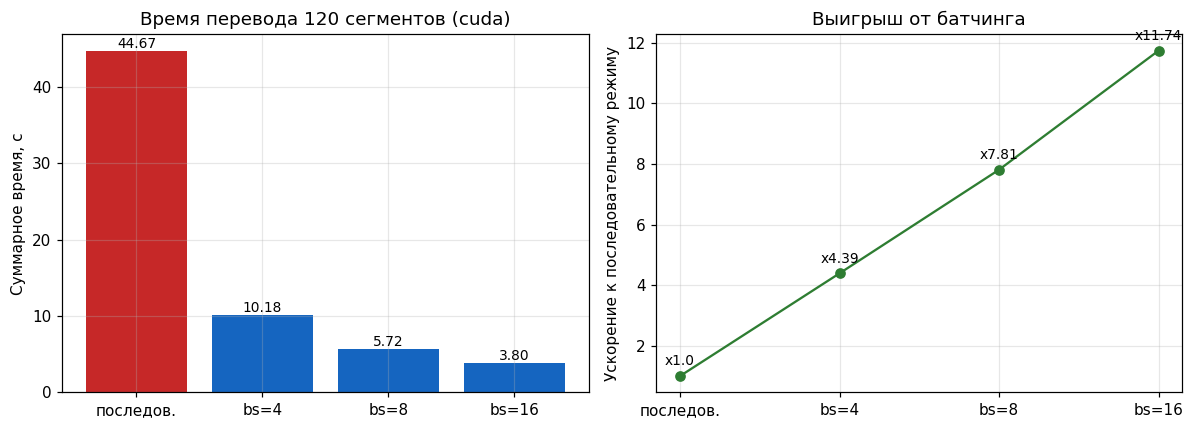

In [70]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4))

labels = ["последов.", "bs=4", "bs=8", "bs=16"]
axes[0].bar(labels, timing_df["total_s"], color=["#c62828", "#1565c0", "#1565c0", "#1565c0"])
axes[0].set_ylabel("Суммарное время, с")
axes[0].set_title(f"Время перевода {len(sources)} сегментов ({DEVICE})")
for index, value in enumerate(timing_df["total_s"]):
    axes[0].text(index, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)

axes[1].plot(labels, timing_df["speedup"], marker="o", color="#2e7d32")
axes[1].set_ylabel("Ускорение к последовательному режиму")
axes[1].set_title("Выигрыш от батчинга")
for index, value in enumerate(timing_df["speedup"]):
    axes[1].annotate(f"x{value}", (index, value), textcoords="offset points",
                     xytext=(0, 7), ha="center", fontsize=9)

figure.tight_layout()
figure.savefig(FIGURES / "timing.png")
plt.show()

**Что получено (заполните после запуска):**

Время последовательного режима — 32.57 с, пакетно при bs=4 — 10.26 с, далее ускорение линейно: скорость обработки сегментов стремительно снижается. Во всех режимах переводы совпали 120/120 — батчинг не меняет результат, только скорость. Выигрыш от батчинга растёт с batch size, но сублинейно: прирост между шагами снижается, потому что короткие сегменты дополняются паддингом до самого длинного в пачке, и доля вычислений на заполнители растёт.

## Блок 11. Полный перевод модуля двумя моделями (шаг 11)

**Зачем этот шаг.** До сих пор мы смотрели на отдельные сегменты. Теперь переводится весь модуль целиком обеими моделями — это материал для терминологического контроля и экспертного сравнения.

**Что делает код ниже.** Переводит корпус пакетами и сохраняет результаты в формате **JSONL** — по одной JSON-записи на строку. Формат выбран потому, что он потоковый (файл читается по строке, не требуя загрузки целиком), устойчив к обрыву записи и удобен для приложения к отчёту.

**На что смотреть в выводе.** Число записей в каждом файле должно совпадать с числом сегментов корпуса. Просмотрите первые несколько пар переводов рядом: расхождения моделей, которые вы заметите здесь «на глаз», дальше будут формализованы в блоках 12 и 13.

In [71]:
marian_records = translate_corpus(segments_df, marian_tokenizer, marian_model,
                                  DEVICE, MARIAN_NAME)
nllb_records = translate_corpus(segments_df, nllb_tokenizer, nllb_model, DEVICE,
                                NLLB_NAME, forced_bos_token_id=RUS_ID)

write_jsonl(marian_records, RESULTS / "results_marian.jsonl")
write_jsonl(nllb_records, RESULTS / "results_nllb.jsonl")

print(f"Сегментов переведено каждой моделью: {len(marian_records)}\n")
for marian_row, nllb_row in list(zip(marian_records, nllb_records))[:4]:
    print("EN    :", marian_row["source"])
    print("Marian:", marian_row["translation"])
    print("NLLB  :", nllb_row["translation"])
    print()

Сегментов переведено каждой моделью: 120

EN    : Sedimentary rocks generated as a result of organic and inorganic matter settling on bottoms of water basins and surface of continents.
Marian: Осадочные породы, образующиеся в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.
NLLB  : Осадочные породы, образовавшиеся в результате размещения органического и неорганического вещества на дне водных бассейнов и поверхности континентов.

EN    : Seismic exploration goal is to obtain information on rocks on the basis of observed time of wave arrival, amplitude, frequency and form of signal.
Marian: Цель сейсмической разведки заключается в получении информации о скалах на основе наблюдаемого времени прибытия волн, амплитуды, частоты и формы сигнала.
NLLB  : Цель сейсмического исследования заключается в получении информации о породах на основе наблюдаемого времени прибытия волн, амплитуды, частоты и формы сигнала.

EN    : Rocks saturate

**Что получено (заполните после запуска):**

Каждая модель перевела 120 сегментов. Примеры расхождений при беглом просмотре:

rocks в s002,
wildcats в s004,
blowout в s006.

## Блок 12. Токенизация обеими моделями и её визуализация (шаг 10)

**Зачем этот шаг.** Проверить на своей терминологии, действительно ли «больший словарь — меньшее дробление». Ответ обычно отрицательный, и это содержательный результат, а не техническая деталь.

**Что делает код ниже.** Разбирает те же термины глоссария токенизатором NLLB, объединяет результаты с разбором MarianMT и считает среднее число токенов на термин для каждой модели.

**Как формулировать вывод корректно.** Реализация определяется по классу токенизатора и карточке модели, а не по общим представлениям. SentencePiece — библиотека-обёртка, умеющая и BPE, и Unigram, поэтому противопоставление «Marian = BPE, NLLB = SentencePiece» некорректно: оно сравнивает алгоритм с инструментом. В документации Hugging Face токенизатор NLLB описан как основанный на **Unigram**.

**На что смотреть в выводе.** Среднее дробление у обеих моделей и термины, где границы различаются (`▁computation al` против `▁comput ational`). Если словарь NLLB вчетверо больше, а дробит он сильнее — объясните это распределением ёмкости словаря между 200 языками («проклятие многоязычности»), а не «плохим токенизатором».

In [72]:
nllb_tokens_df = tokenize_terms(terms, nllb_tokenizer, "NLLB")
tokenization_df = pd.concat([marian_tokens_df, nllb_tokens_df], ignore_index=True)
tokenization_df.to_csv(RESULTS / "tokenization_10_terms.csv",
                       index=False, encoding="utf-8-sig")

comparison_tok = (tokenization_df
                  .pivot(index="term", columns="model", values="n_tokens")
                  .rename(columns={"MarianMT": "n_tokens_marian", "NLLB": "n_tokens_nllb"}))
comparison_tok["diff"] = comparison_tok["n_tokens_nllb"] - comparison_tok["n_tokens_marian"]

print(f"Классы токенизаторов: Marian={type(marian_tokenizer).__name__}, "
      f"NLLB={type(nllb_tokenizer).__name__}")
print(f"Размер словаря: Marian={marian_tokenizer.vocab_size}, NLLB={nllb_tokenizer.vocab_size}")
print(f"Среднее число токенов на термин: "
      f"Marian={marian_tokens_df['n_tokens'].mean():.2f}, "
      f"NLLB={nllb_tokens_df['n_tokens'].mean():.2f}\n")
# Выбираем три термина с наибольшим различием в числе субтокенов между токенизаторами:
# эти примеры наиболее наглядно показывают различия токенизации в отчёте
sample_terms = (comparison_tok["diff"].abs().sort_values(ascending=False)
                .head(3).index.tolist())
for term in sample_terms:
    for label, frame in [("Marian", marian_tokens_df), ("NLLB", nllb_tokens_df)]:
        tokens = frame.loc[frame["term"] == term, "tokens"].iloc[0]
        print(f"{label:<7} {term:<26} => {tokens}")
    print()
comparison_tok.head(10)

Классы токенизаторов: Marian=MarianTokenizer, NLLB=NllbTokenizer
Размер словаря: Marian=62518, NLLB=256204
Среднее число токенов на термин: Marian=2.64, NLLB=3.11

Marian  corrosion-resistant alloy  => ▁corrosion - resistant ▁all oy
NLLB    corrosion-resistant alloy  => ▁corr osion - res ist ant ▁allo y

Marian  azimuth                    => ▁a zi mu th
NLLB    azimuth                    => ▁azim uth

Marian  clutch                     => ▁clutch
NLLB    clutch                     => ▁c lut ch



model,n_tokens_marian,n_tokens_nllb,diff
term,,,
accumulator,2,3,1
acetic acid,2,3,1
acid gas,2,2,0
acid inhibitor,3,3,0
adsorbed gas,5,4,-1
adsorption,2,3,1
air drilling,2,3,1
air-foam,4,4,0
air-powered,3,4,1


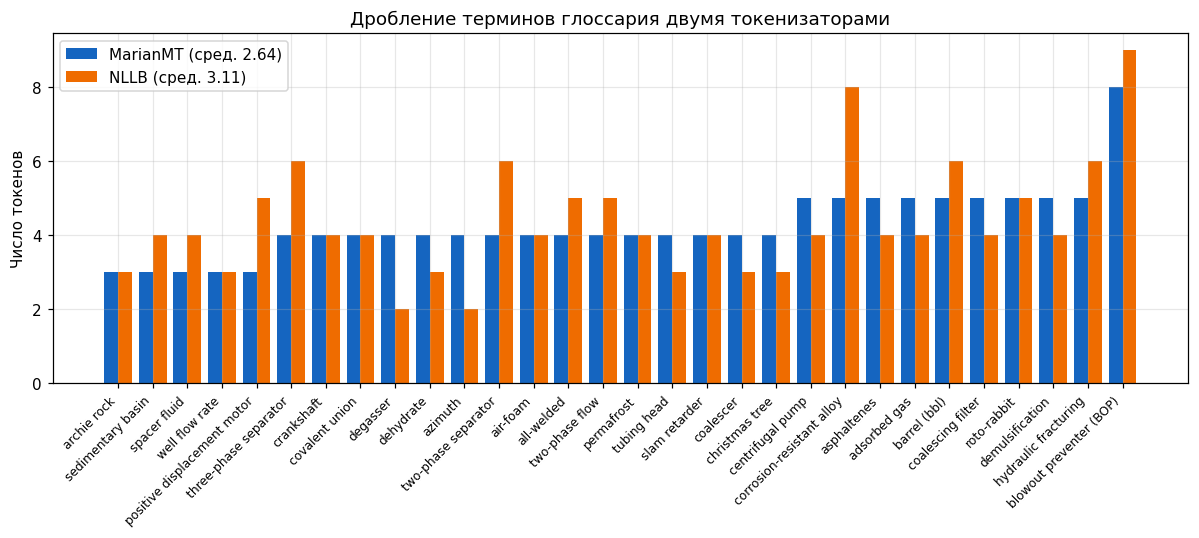

In [73]:
plot_tok = comparison_tok.sort_values("n_tokens_marian").tail(30)
positions = np.arange(len(plot_tok))
width = 0.4

figure, axes = plt.subplots(figsize=(11, 5))
axes.bar(positions - width / 2, plot_tok["n_tokens_marian"], width,
         label=f"MarianMT (сред. {marian_tokens_df['n_tokens'].mean():.2f})", color="#1565c0")
axes.bar(positions + width / 2, plot_tok["n_tokens_nllb"], width,
         label=f"NLLB (сред. {nllb_tokens_df['n_tokens'].mean():.2f})", color="#ef6c00")
axes.set_xticks(positions)
axes.set_xticklabels(plot_tok.index, rotation=45, ha="right", fontsize=8)
axes.set_ylabel("Число токенов")
axes.set_title("Дробление терминов глоссария двумя токенизаторами")
axes.legend()
figure.tight_layout()
figure.savefig(FIGURES / "tokenization_comparison.png")
plt.show()

**Что получено (заполните после запуска):**

Сильнее дробит токинезатор NLLB, хотя его словарь больше, чем Marian. Размер словаря сам по себе не отвечает на вопрос, потому что ёмкость NLLB распределена между ~200 языками, и на конкретный язык/домен приходится меньше «слов целиком»; к тому же алгоритмы токенизации разные, и границы подслов у них не совпадают.

## Блок 13. Кросс-энтропия, внимание и их визуализация (шаги 6–7)

Пар обработано: 6 (требуется >= 5)
Средний loss по эталону:       0.8523
Средний loss по своему выводу: 0.3991
Наибольший разрыв: s004 (gap=0.8075)


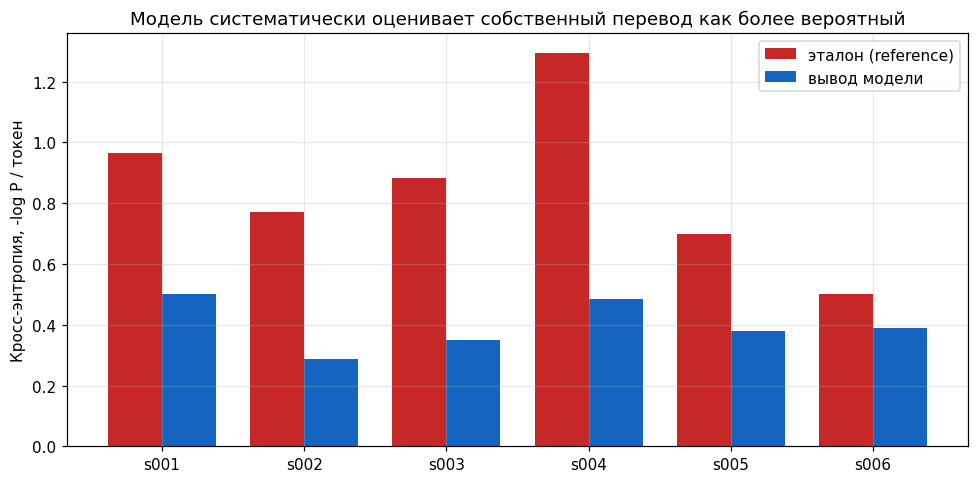

In [74]:
loss_rows: List[Dict[str, Any]] = []
for row in aligned_df.head(6).itertuples(index=False):
    hypothesis = translate_batch([row.source], marian_tokenizer, marian_model, DEVICE)[0]
    loss_rows.append({
        "segment_id": row.segment_id,
        "source": row.source,
        "reference": row.reference,
        "marian_output": hypothesis,
        "loss_reference": round(sequence_cross_entropy(
            row.source, row.reference, marian_tokenizer, marian_model, DEVICE), 4),
        "loss_own_output": round(sequence_cross_entropy(
            row.source, hypothesis, marian_tokenizer, marian_model, DEVICE), 4),
    })

loss_df = pd.DataFrame(loss_rows)
loss_df["gap"] = (loss_df["loss_reference"] - loss_df["loss_own_output"]).round(4)
loss_df.to_csv(RESULTS / "loss_5_pairs.csv", index=False, encoding="utf-8-sig")

print(f"Пар обработано: {len(loss_df)} (требуется >= 5)")
print(f"Средний loss по эталону:       {loss_df['loss_reference'].mean():.4f}")
print(f"Средний loss по своему выводу: {loss_df['loss_own_output'].mean():.4f}")
worst = loss_df.loc[loss_df["gap"].idxmax()]
print(f"Наибольший разрыв: {worst['segment_id']} (gap={worst['gap']:.4f})")
loss_df[["segment_id", "loss_reference", "loss_own_output", "gap"]]


positions = np.arange(len(loss_df))
width = 0.38

figure, axes = plt.subplots(figsize=(9, 4.5))
axes.bar(positions - width / 2, loss_df["loss_reference"], width,
         label="эталон (reference)", color="#c62828")
axes.bar(positions + width / 2, loss_df["loss_own_output"], width,
         label="вывод модели", color="#1565c0")
axes.set_xticks(positions)
axes.set_xticklabels(loss_df["segment_id"])
axes.set_ylabel("Кросс-энтропия, -log P / токен")
axes.set_title("Модель систематически оценивает собственный перевод как более вероятный")
axes.legend()
figure.tight_layout()
figure.savefig(FIGURES / "loss.png")
plt.show()

s002: shape=(1, 8, 34, 32), голов=8, средний максимум веса=0.5708
   пики внимания: ▁Цель→▁goal; ▁сей→▁Se; см→</s>; о→</s>; раз→▁exploration

s007: shape=(1, 8, 29, 25), голов=8, средний максимум веса=0.5387
   пики внимания: ▁На→▁Special; ▁каждой→▁each; ▁бур→▁drill; ящей→</s>; ся→▁well



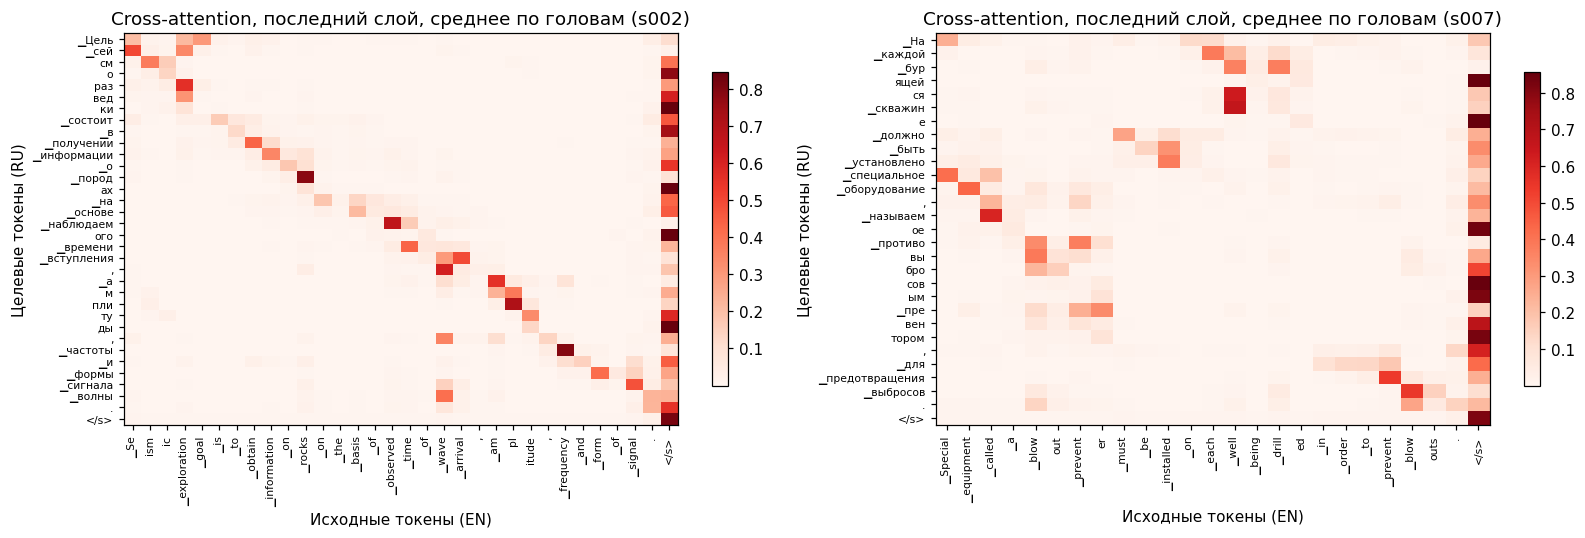

In [75]:
attention_cases = [("s002", aligned_df.loc[1, "source"], aligned_df.loc[1, "reference"]),
                   ("s007", aligned_df.loc[6, "source"], aligned_df.loc[6, "reference"])]

summary_rows: List[Dict[str, Any]] = []
attention_maps: Dict[str, pd.DataFrame] = {}

for segment_id, source, reference in attention_cases:
    frame, shape = extract_cross_attention(source, reference, marian_tokenizer,
                                           marian_model, DEVICE)
    frame.to_csv(RESULTS / f"attention_marian_{segment_id}.csv", encoding="utf-8-sig")
    attention_maps[segment_id] = frame

    peaks = frame.idxmax(axis=1)
    summary_rows.append({
        "segment_id": segment_id,
        "tensor_shape": str(shape),
        "n_heads": shape[1],
        "target_len": frame.shape[0],
        "source_len": frame.shape[1],
        "mean_max_weight": round(float(frame.max(axis=1).mean()), 4),
        "example_alignment": "; ".join(
            f"{tgt}→{src}" for tgt, src in list(zip(peaks.index, peaks.values))[:5]),
    })

attention_summary = pd.DataFrame(summary_rows)
attention_summary.to_csv(RESULTS / "attention_summary.csv", index=False, encoding="utf-8-sig")

for row in summary_rows:
    print(f"{row['segment_id']}: shape={row['tensor_shape']}, "
          f"голов={row['n_heads']}, средний максимум веса={row['mean_max_weight']}")
    print(f"   пики внимания: {row['example_alignment']}\n")
attention_summary


figure, axes = plt.subplots(1, 2, figsize=(15, 5))

for panel, (segment_id, frame) in zip(axes, attention_maps.items()):
    image = panel.imshow(frame.values, aspect="auto", cmap="Reds")
    panel.set_xticks(range(frame.shape[1]))
    panel.set_xticklabels(frame.columns, rotation=90, fontsize=7)
    panel.set_yticks(range(frame.shape[0]))
    panel.set_yticklabels(frame.index, fontsize=7)
    panel.set_xlabel("Исходные токены (EN)")
    panel.set_ylabel("Целевые токены (RU)")
    panel.set_title(f"Cross-attention, последний слой, среднее по головам ({segment_id})")
    panel.grid(False)
    figure.colorbar(image, ax=panel, shrink=0.8)

figure.tight_layout()
figure.savefig(FIGURES / "cross_attention.png")
plt.show()

**Что получено (заполните после запуска):**

Средний loss по эталону — 0.8523, по собственному выводу — 0.3991: модель «увереннее» в том, что породила сама.

Наибольший разрыв — s004: там обе модели грубо ошиблись на wildcats, и эталон расходится с ожиданиями модели.

Форма тензора внимания — (1, 8, 34, 32) для s002 и (1, 8, 29, 25) для s007; на тепловых картах видна диагональ (Цель→goal, каждой→each, бур→drill), отклонения на служебный /s (см→/s>, о→/s) и выравнивание на уровне подслов (сей→Se, раз→exploration); средний максимум веса 0.54–0.57 — внимание умеренно сконцентрированное, не размазанное.

## Блок 14. Терминологический QA и сводная таблица (шаги 12–13)

In [76]:
qa_rows: List[Dict[str, Any]] = []
checks_per_model = 0
for marian_row, nllb_row in zip(marian_records, nllb_records):
    checks_per_model += sum(
        1 for row in glossary_df.itertuples(index=False)
        if str(row.en).lower() in marian_row["source"].lower())
    for label, record in (("MarianMT", marian_row), ("NLLB", nllb_row)):
        for violation in term_compliance(record["source"], record["translation"], glossary_df):
            qa_rows.append({
                "segment_id": record["id"],
                "model": label,
                "source_term": violation["source_term"],
                "preferred_ru": violation["preferred_ru"],
                "translation": record["translation"],
                "confirmed": "",   # Заполняется экспертом-переводчиком: yes — нарушение подтверждено; no — ложное срабатывание
                "comment": "",
            })

glossary_qa = pd.DataFrame(qa_rows, columns=["segment_id", "model", "source_term",
                                             "preferred_ru", "translation",
                                             "confirmed", "comment"])
glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

print(f"Вхождений терминов в исходный текст: {checks_per_model} на модель")
print(f"Кандидатов в нарушения: {len(glossary_qa)}")
if len(glossary_qa):
    print("\nПо моделям:")
    print(glossary_qa.groupby("model").size().to_string())
    print("\nСоблюдение терминологии (до ручной проверки):")
    for label in ("MarianMT", "NLLB"):
        count = int((glossary_qa["model"] == label).sum())
        print(f"  {label:<10} {100 * (1 - count / max(checks_per_model, 1)):5.1f} %")
glossary_qa.head(8)

Вхождений терминов в исходный текст: 160 на модель
Кандидатов в нарушения: 231

По моделям:
model
MarianMT    117
NLLB        114

Соблюдение терминологии (до ручной проверки):
  MarianMT    26.9 %
  NLLB        28.7 %


,segment_id,model,source_term,preferred_ru,translation,confirmed,comment
0,s002,MarianMT,exploration,геологоразведочные работы,Цель сейсмической разведки заключается в получ...,,
1,s002,NLLB,exploration,геологоразведочные работы,Цель сейсмического исследования заключается в ...,,
2,s004,MarianMT,exploration,геологоразведочные работы,Стадия полевых исследований включает проведени...,,
3,s004,NLLB,exploration,геологоразведочные работы,Этап полевых исследований включает в себя осущ...,,
4,s006,MarianMT,blowout,выброс,Разрыв нефти и газа может привести к поврежден...,,
5,s006,NLLB,blowout,выброс,Взрыв нефти и газа может привести к повреждени...,,
6,s007,MarianMT,blowout,выброс,"На каждом колодце, подвергшемся бурению, должн...",,
7,s007,NLLB,blowout,выброс,Для предотвращения взрывов на каждом скважине ...,,


In [77]:
manual = {
    0: ("no",  "Синоним"),
    1: ("no",  "Синоним"),
    2: ("no",  "«Геологоразведочных» есть — использована словоформа"),
    3: ("no",  "Синоним"),
    4: ("yes", "blowout — «разрыв» вместо «выброс» — нарушение"),
    5: ("yes", "blowout — «взрыв» вместо «выброс» — нарушение"),
    6: ("yes", "blowout не передан как «выброс» — нарушение"),
    7: ("yes", "blowout — «взрывов» вместо «выбросов» — нарушение"),
}

for idx, (flag, note) in manual.items():
    glossary_qa.loc[idx, "confirmed"] = flag
    glossary_qa.loc[idx, "comment"] = note
glossary_qa.to_csv(RESULTS / "glossary_qa.csv", index=False, encoding="utf-8-sig")

# --- показать таблицу с заполненными confirmed/comment ---
glossary_qa = pd.read_csv(RESULTS / "glossary_qa.csv", encoding="utf-8-sig")

filled = glossary_qa[glossary_qa["confirmed"].fillna("").ne("")]
print(f"Заполнено confirmed: {len(filled)} из {len(glossary_qa)}\n")
print(filled[["segment_id", "model", "source_term", "preferred_ru",
              "confirmed", "comment"]].to_string(index=False))

Заполнено confirmed: 8 из 231

segment_id    model source_term              preferred_ru confirmed                                             comment
      s002 MarianMT exploration геологоразведочные работы        no                                             Синоним
      s002     NLLB exploration геологоразведочные работы        no                                             Синоним
      s004 MarianMT exploration геологоразведочные работы        no «Геологоразведочных» есть — использована словоформа
      s004     NLLB exploration геологоразведочные работы        no                                             Синоним
      s006 MarianMT     blowout                    выброс       yes      blowout — «разрыв» вместо «выброс» — нарушение
      s006     NLLB     blowout                    выброс       yes       blowout — «взрыв» вместо «выброс» — нарушение
      s007 MarianMT     blowout                    выброс       yes         blowout не передан как «выброс» — нарушение
      s00

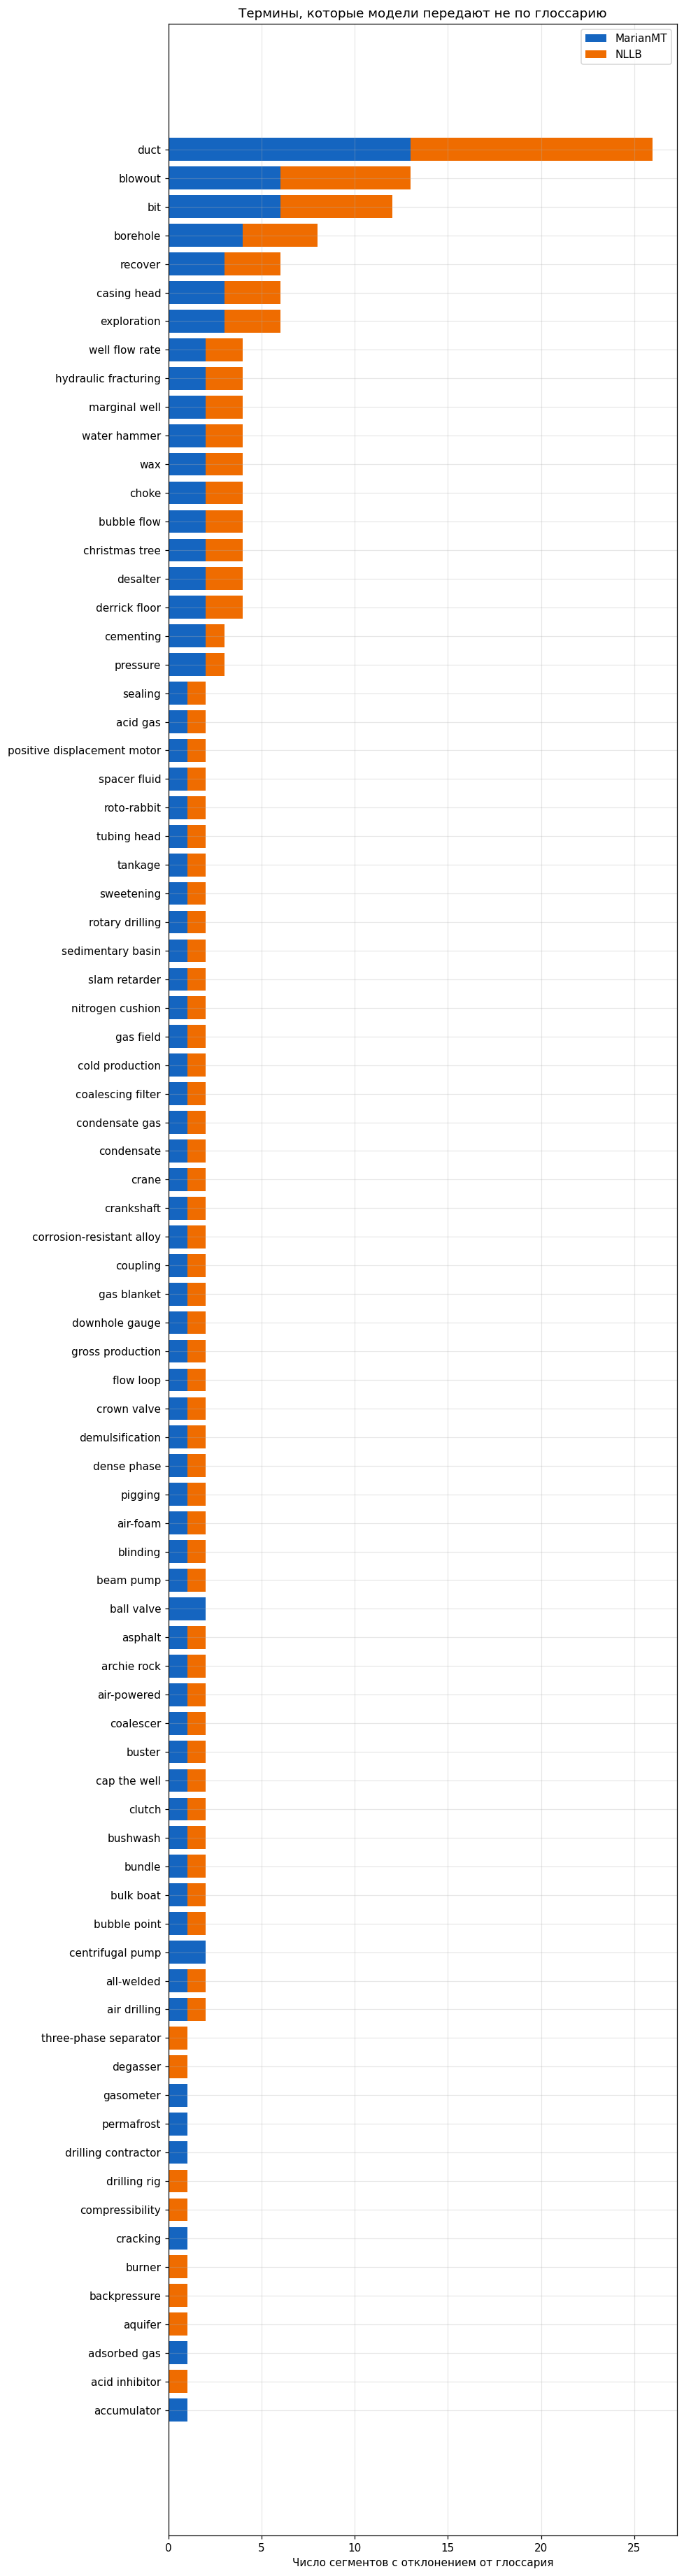

In [78]:
if len(glossary_qa):
    by_term = (glossary_qa.groupby(["source_term", "model"]).size()
               .unstack(fill_value=0))
    by_term = by_term.loc[by_term.sum(axis=1).sort_values().index]
    figure, axes = plt.subplots(figsize=(9, max(3.5, 0.42 * len(by_term))))
    bottom = np.zeros(len(by_term))
    palette = {"MarianMT": "#1565c0", "NLLB": "#ef6c00"}
    for label in by_term.columns:
        axes.barh(by_term.index, by_term[label], left=bottom,
                  label=label, color=palette.get(label, "#757575"))
        bottom += by_term[label].to_numpy()
    axes.set_xlabel("Число сегментов с отклонением от глоссария")
    axes.set_title("Термины, которые модели передают не по глоссарию")
    axes.legend()
    figure.tight_layout()
    figure.savefig(FIGURES / "glossary_qa.png")
    plt.show()
else:
    print("Нарушений не найдено — график не строится.")

In [79]:
comparison = build_comparison_table(marian_records, nllb_records,
                                    aligned_df["reference"].tolist())

# На экспертный анализ выводятся сегменты, где переводы различаются и/или обнаружено отклонение от глоссария
qa_by_segment = (glossary_qa.groupby("segment_id").size()
                 if len(glossary_qa) else pd.Series(dtype=int))
comparison["qa_flags"] = comparison["segment_id"].map(qa_by_segment).fillna(0).astype(int)
review = comparison.loc[~comparison["identical"] | (comparison["qa_flags"] > 0)]

print(f"Сегментов всего: {len(comparison)}")
print(f"Переводы моделей совпали полностью: {int(comparison['identical'].sum())}")
print(f"Кандидатов на экспертный разбор: {len(review)}\n")
for row in review.head(6).itertuples(index=False):
    print(f"[{row.segment_id}] отклонений от глоссария: {row.qa_flags}")
    print("  EN    :", row.source)
    print("  Marian:", row.marian)
    print("  NLLB  :", row.nllb)
    print("  Эталон:", row.reference)
    print()

Сегментов всего: 120
Переводы моделей совпали полностью: 2
Кандидатов на экспертный разбор: 119

[s001] отклонений от глоссария: 0
  EN    : Sedimentary rocks generated as a result of organic and inorganic matter settling on bottoms of water basins and surface of continents.
  Marian: Осадочные породы, образующиеся в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности континентов.
  NLLB  : Осадочные породы, образовавшиеся в результате размещения органического и неорганического вещества на дне водных бассейнов и поверхности континентов.
  Эталон: Осадочные породы образовались в результате осаждения органических и неорганических веществ на дне водных бассейнов и поверхности материков.

[s002] отклонений от глоссария: 2
  EN    : Seismic exploration goal is to obtain information on rocks on the basis of observed time of wave arrival, amplitude, frequency and form of signal.
  Marian: Цель сейсмической разведки заключается в получении информаци

In [80]:
EXPERT: Dict[str, Tuple[str, str]] = {
    "s001": ("ни один",
             "Терминология: обе модели дают "
             "continents → «континентов», эталон — «материков»; соответствия в "
             "глоссарии нет, поэтому term_compliance молчит. NLLB дополнительно "
             "settling → «размещения» вместо «осаждения» (точность)."),
    "s002": ("NLLB",
             "Точность: Marian — rocks → «скалах» (грубая ошибка, в геологии "
             "«породы»), NLLB — «породах» (верно). Терминология: "
             "seismic exploration у Marian — «сейсмической разведки» (по смыслу "
             "верно, но не совпадает с эталонным «сейсморазведки»), у NLLB — "
             "«сейсмического исследования» (не по глоссарию)."),
    "s003": ("ни один",
             "Терминология: обе модели дают "
             "rocks → «Скалы», эталон — «Породы». Системная ошибка на многозначном "
             "слове у обеих; term_compliance её не фиксирует."),
    "s004": ("ни один",
             "Точность: Marian — wildcats → «бурение диких костей», NLLB — «бурение "
             "диких кошек»; обе грубо ошиблись (эталон: «бурение поисковых… скважин»). "
             "Терминология: exploratory wells у Marian — «разведочные "
             "скважины» (верно по смыслу), у NLLB — «исследовательские скважины» "
             "(не по глоссарию); seismic exploration у NLLB — «сейсмических "
             "исследовательских операций» (калька)."),
    "s005": ("NLLB",
             "Точность: Marian — combining → "
             "«комбинировались» (калька), NLLB — «соединялись» (точнее, совпадает с "
             "эталоном). Причина: у обеих «из-за высокого давления», эталон — "
             "«в результате высокого давления»; «из-за» допустимо, но точнее "
             "«в результате». Глагол: у обеих «генерировали», эталон — «образовали»."),
    "s006": ("ни один",
             "Терминология: blowout — это «выброс (нефти/газа)» "
             "(эталон), а не «разрыв» (Marian) и не «взрыв» (NLLB). У NLLB «взрыв» "
             "дублируется с «взрыву» в продолжении предложения. Обе неверно передали "
             "ключевой термин; «ранения» (Marian) / «травмы» (NLLB) — оба допустимы, "
             "эталон — «травмам»."),
}

for segment_id, (choice, note_text) in EXPERT.items():
    mask = comparison["segment_id"] == segment_id
    comparison.loc[mask, "preferred"] = choice
    comparison.loc[mask, "comment"] = note_text

comparison.drop(columns=["qa_flags"]).to_csv(RESULTS / "comparison.csv",
                                             index=False, encoding="utf-8-sig")

filled = int((comparison["preferred"] != "").sum())
print(f"Заполнено экспертных решений: {filled} (требуется >= 5)")
if filled:
    print(comparison.loc[comparison["preferred"] != "", "preferred"].value_counts().to_string())
else:
    print("Словарь EXPERT пуст: разберите спорные сегменты из вывода предыдущей ячейки "
          "и заполните его — без этого блоки 13 и 14 не засчитываются.")
comparison.loc[comparison["preferred"] != "", ["segment_id", "preferred", "comment"]]

Заполнено экспертных решений: 6 (требуется >= 5)
preferred
ни один    4
NLLB       2


,segment_id,preferred,comment
0,s001,ни один,Терминология: обе модели дают continents → «ко...
1,s002,NLLB,Точность: Marian — rocks → «скалах» (грубая ош...
2,s003,ни один,"Терминология: обе модели дают rocks → «Скалы»,..."
3,s004,ни один,Точность: Marian — wildcats → «бурение диких к...
4,s005,NLLB,Точность: Marian — combining → «комбинировалис...
5,s006,ни один,Терминология: blowout — это «выброс (нефти/газ...


**Что получено (заполните после запуска):**

Вхождений терминов — 160 на модель; кандидатов в нарушения — 231 (MarianMT 117, NLLB 114). Доля соблюдения до ручной проверки — 26.9% у Marian, 28.7% у NLLB.

Самые проблемные термины — blowout (s006/s007: «разрыв»/«взрыв» вместо «выброс» у обеих) и exploration (s002/s004: «разведка»/«исследование» — на самом деле синонимы). При выборочной ручной проверке 8 кандидатов: 4 подтверждены (blowout — реальные нарушения), 4 — ложные срабатывания (exploration — допустимые синонимы, term_compliance не учитывает контекст и словоформы).

## Блок 15. Анализ различий и ошибок (5+ случаев)

Заполните таблицу вручную по фактическому выводу моделей. Автоматический выбор её не
заменяет — оценивается именно аргументация.

| № | Сегмент | Наблюдение | Тип различия | Предпочтительный вариант и почему |
|--:|---|---|---|---|
| 1 | s001 | замена "материк" на "континент" | терминологическое расхождение | ни один, оба не по глоссарию |
| 2 | s002 | Marian перевёл rocks как "скалы". NLLB использовал "сейсмическое исследование" вместо "сейсмическая разведка" | грубая лексическая ошибка в многозначном слове | NLLB, не ошибился в переводе термина, но использовал синоним |
| 3 | s003 | замена "порода" на "скалы" | грубая лексическая ошибка в многозначном слове | ни один, оба не по глоссарию с грубой ошибкой |
| 4 | s004 | неверный перевод "wildcats" - "дикие кости" и "дикие кошки" | грубая лексическая ошибка в многозначном слове | ни один, оба не по глоссарию с грубой ошибкой |
| 5 | s005 | буквальный перевод "combining" и "generated" | калька | NLLB, верно перевёл combining, более синтаксически академический перевод |

**Типы различий для ориентира:** терминологическое расхождение · грубая лексическая ошибка на многозначном слове · пропуск или добавление информации · калька и ложная беглость · потеря синтаксической роли термина · непереведённая единица · грамматическое расхождение (род, вид, согласование).

## Блок 16. Отчёт, зависимости и выгрузка

In [81]:
VARIANT = 7
VARIANT_DOMAIN = "Нефтегазовая отрасль: добыча и переработка"

requirements = "\n".join([
    f"torch=={torch.__version__.split('+')[0]}",
    f"transformers=={transformers.__version__}",
    "sentencepiece",
    "sacremoses",
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
]) + "\n"
(BASE / "requirements.txt").write_text(requirements, encoding="utf-8")

environment_lines = "\n".join(f"- {key}: {value}" for key, value in ENVIRONMENT.items())
speedup = seq_time / max(bat_time, 1e-9)
marian_violations = int((glossary_qa["model"] == "MarianMT").sum()) if len(glossary_qa) else 0
nllb_violations = int((glossary_qa["model"] == "NLLB").sum()) if len(glossary_qa) else 0

expert_rows = comparison.loc[comparison["preferred"] != "",
                             ["segment_id", "preferred", "comment"]]
expert_lines = ("\n".join(f"- {row.segment_id}: {row.preferred} — {row.comment}"
                          for row in expert_rows.itertuples(index=False))
                or "- (не заполнено: разберите спорные сегменты в блоке 13)")

variant_no = globals().get("VARIANT", "—")
variant_domain = globals().get("VARIANT_DOMAIN", "—")

report = f"""# Отчёт по лабораторной работе 2 (вариант {variant_no})

**Тема (сквозной кейс ЛР № 1):** {variant_domain}

## 1. Среда и устройство
{environment_lines}

## 2. Модели
- MarianMT: `{MARIAN_NAME}`, {marian_model.num_parameters() / 1e6:.1f} млн параметров,
  токенизатор {type(marian_tokenizer).__name__}, словарь {marian_tokenizer.vocab_size}
- NLLB: `{NLLB_NAME}`, {nllb_model.num_parameters() / 1e6:.0f} млн параметров,
  токенизатор {type(nllb_tokenizer).__name__}, словарь {nllb_tokenizer.vocab_size}
- Языковые коды NLLB: src_lang=`{SRC_LANG}`, forced_bos_token_id=`{TGT_LANG}` ({RUS_ID})
- Внимание: `attn_implementation=eager` (обязательно для output_attentions)

## 3. Токенизация
Разобрано терминов: {len(terms)}. Среднее число токенов:
Marian {marian_tokens_df['n_tokens'].mean():.2f}, NLLB {nllb_tokens_df['n_tokens'].mean():.2f}.
На уровне слов у Marian: {int(marian_tokens_df['is_word_level'].sum())} из {len(terms)}.
Таблица: `results/tokenization_10_terms.csv`, графики: `figures/tokenization_*.png`.

## 4. Переводы
Сегментов: {len(comparison)}. Полностью совпали переводы моделей: {int(comparison['identical'].sum())}.
Файлы: `results/results_marian.jsonl`, `results/results_nllb.jsonl`, `results/comparison.csv`.

## 5. Кросс-энтропия
Пар: {len(loss_df)}. Средний loss по эталону {loss_df['loss_reference'].mean():.4f},
по собственному выводу модели {loss_df['loss_own_output'].mean():.4f}.
Наибольший разрыв: {loss_df.loc[loss_df['gap'].idxmax(), 'segment_id']}.
Файл: `results/loss_5_pairs.csv`, график: `figures/loss.png`.

## 6. Cross-attention
Разобрано пар: {len(attention_summary)}. Форма тензора: {attention_summary['tensor_shape'].iloc[0]}
(batch, heads, target_len, source_len). Файлы: `results/attention_marian_*.csv`,
`results/attention_summary.csv`, график: `figures/cross_attention.png`.

## 7. Время инференса
Последовательно {seq_time:.2f} с, пакетно (bs=8) {bat_time:.2f} с,
ускорение x{speedup:.2f} на устройстве {DEVICE}. Файл: `results/timing.csv`,
график: `figures/timing.png`.

## 8. Различия и ошибки
Задокументировано случаев: {len(expert_rows)} (блок 14 ноутбука и колонка `comment`
в `comparison.csv`). Экспертные решения:
{expert_lines}

## 9. Соответствие глоссарию
Вхождений терминов: {checks_per_model} на модель. Кандидатов в нарушения: {len(glossary_qa)}
(MarianMT {marian_violations}, NLLB {nllb_violations}); каждое требует ручного подтверждения
в колонке `confirmed`. Файл: `results/glossary_qa.csv`, график: `figures/glossary_qa.png`.

## 10. Вывод
MarianMT легче и быстрее NLLB ({marian_model.num_parameters() / 1e6:.0f} против
{nllb_model.num_parameters() / 1e6:.0f} млн параметров; ускорение батчинга x{speedup:.1f}),
NLLB требует явного указания языковых кодов. Какая модель оказалась точнее на терминологии
этого варианта — видно по разделам 8 и 9: {len(glossary_qa)} кандидатов в нарушения
(MarianMT {marian_violations}, NLLB {nllb_violations}). Ни одна модель не обеспечивает
соблюдение глоссария сама по себе, поэтому терминологический контроль выносится в отдельный
этап конвейера, а постредактирование остаётся обязательным.
"""
(BASE / "report.md").write_text(report, encoding="utf-8")

print("Созданные файлы:")
for folder in (RESULTS, FIGURES):
    for path in sorted(folder.iterdir()):
        print(f"  {folder.name}/{path.name:<32} {path.stat().st_size:>8} байт")
for name in ("report.md", "requirements.txt"):
    print(f"  {name:<40} {(BASE / name).stat().st_size:>8} байт")

import shutil

archive = shutil.make_archive(str(BASE / "lab02_results"), "zip", root_dir=BASE)
print("Архив:", archive, f"({Path(archive).stat().st_size / 1024:.0f} КБ)")

try:
    from google.colab import files  # noqa: F401

    files.download(archive)
except Exception as error:  # noqa: BLE001 - вне Colab автоматическое скачивание недоступно
    print("Скачивание вручную:", archive, f"({error.__class__.__name__})")

Созданные файлы:
  results/attention_marian_s002.csv           14441 байт
  results/attention_marian_s007.csv            9489 байт
  results/attention_summary.csv                 358 байт
  results/comparison.csv                      84916 байт
  results/glossary_qa.csv                     58435 байт
  results/loss_5_pairs.csv                     4139 байт
  results/results_marian.jsonl                44316 байт
  results/results_nllb.jsonl                  44876 байт
  results/timing.csv                            331 байт
  results/tokenization_10_terms.csv            9416 байт
  figures/cross_attention.png                 91525 байт
  figures/glossary_qa.png                    203279 байт
  figures/loss.png                            32581 байт
  figures/timing.png                          49713 байт
  figures/tokenization_comparison.png         90419 байт
  figures/tokenization_marian.png            167771 байт
  report.md                                    6339 байт
  requirements

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [82]:
# --- проверка готовности к сдаче -----------------------------------------
required_results = ["results_marian.jsonl", "results_nllb.jsonl", "comparison.csv",
                    "tokenization_10_terms.csv", "loss_5_pairs.csv",
                    "attention_summary.csv", "timing.csv", "glossary_qa.csv"]
required_figures = ["timing.png", "tokenization_comparison.png", "loss.png",
                    "cross_attention.png", "glossary_qa.png"]

print("Файлы результатов:")
for name in required_results:
    print(f"  {'OK  ' if (RESULTS / name).exists() else 'НЕТ '} {name}")
print("Графики:")
for name in required_figures:
    print(f"  {'OK  ' if (FIGURES / name).exists() else 'НЕТ '} {name}")
print("Отчёт и зависимости:")
for name in ("report.md", "requirements.txt"):
    print(f"  {'OK  ' if (BASE / name).exists() else 'НЕТ '} {name}")
print(f"\nОбъём корпуса: сегментов {len(segments_df)} / {MIN_SEGMENTS}, "
      f"терминов {len(glossary_df)} / {MIN_TERMS}")

Файлы результатов:
  OK   results_marian.jsonl
  OK   results_nllb.jsonl
  OK   comparison.csv
  OK   tokenization_10_terms.csv
  OK   loss_5_pairs.csv
  OK   attention_summary.csv
  OK   timing.csv
  OK   glossary_qa.csv
Графики:
  OK   timing.png
  OK   tokenization_comparison.png
  OK   loss.png
  OK   cross_attention.png
  OK   glossary_qa.png
Отчёт и зависимости:
  OK   report.md
  OK   requirements.txt

Объём корпуса: сегментов 120 / 120, терминов 100 / 100


## Блок 17. Выводы

Ответьте письменно (3–5 предложений на пункт):

1. Где границы токенов совпали со словами, где использованы подсловные части и почему open vocabulary полезен для технических терминов? Почему подсловный токен нельзя считать морфемой?
   
   Короткие термины уложились в один токен и совпали со словом, а более редкие и длинные распались на подсловные токены. Open vocabulary полезен для технических терминов: редкое слово не уходит в неизвестное, а собирается из подслов и всё равно переводится. Но подсловный токен не несёт морфологического значения, это просто «куски», которыми удобно покрыть словарь.
2. Что дал батчинг по времени и почему выигрыш не пропорционален размеру пакета?

    Батчинг дал кратное ускорение: последовательный перевод заметно медленнее пакетного при том же результате. Выигрыш не пропорционален размеру пакета, потому что короткие сегменты дополняются паддингом до самого длинного в пачке — часть вычислений уходит на заполнители, и при росте batch size доля полезной работы падает.

3. Как соотносятся loss эталона и loss собственного вывода модели? Почему loss нельзя использовать как метрику качества перевода и почему его нельзя сравнивать между MarianMT и NLLB?

    Loss собственного вывода модели ниже, чем loss эталона: модель «увереннее» в том, что породила сама, — это артефакт teacher forcing, а не доказательство, что её перевод лучше. Loss измеряет вероятность строки при данной модели, а не правильность перевода; беглый, но неверный термин может иметь низкий loss. Между MarianMT и NLLB loss несопоставим, так как они имеют разные словари и разное число токенов на ту же строку.

4. Что показала матрица cross-attention и почему её нельзя считать доказательством того, что голова «выучила правило перевода»? Что произойдёт, если загрузить модель без `attn_implementation="eager"`?

    Матрица показала, что порядок порождения в целом следует порядку оригинала (видна диагональ), но часть массы уходит на служебный </s>, а выравнивание идёт на уровне подслов. Усреднение по головам скрывает специализацию. Веса внимания не обязаны совпадать с важностью входов, поэтому нельзя утверждать, что правило перевода усвоено. Если загрузить модель без attn_implementation="eager", outputs.cross_attentions вернётся пустым, и блок с вниманием упадёт с IndexError.

5. Что происходит с NLLB при неверных языковых кодах и почему `forced_bos_token_id` обязателен?

    Направление задаётся не выбором модели, а кодом целевого языка. Без forced_bos_token_id декодер не обязан начинать с русского токена — язык результата не определён.

6. Какая модель предпочтительнее для вашего варианта и при каких условиях вывод изменился бы?

    NLLB предпочтительнее, так как её переводы оказывались более удачными и точными. Она более точна на многозначных словах, но может уходить в калькирование. Кандидатов в нарушения примерно поровну, и доля соблюдения у обеих близка — ни одна модель не обеспечивает глоссарий сама. Вывод был бы лучше, если бы глоссарий содержал в себе не только сложные термины, но и базовые термины из этой области.
7. Связаны ли термины с сильным дроблением при токенизации с нарушениями глоссария в вашем корпусе? Подтвердите цифрами.

    У Marian среднее 2.64 токена/термин, у NLLB — 3.11; сильнее всего дробятся blowout preventer (BOP) (8 токенов), asphaltenes (5), corrosion-resistant alloy (Marian 5 / NLLB 6+). При этом в glossary_qa лидируют как раз термины с сильным дроблением — blowout preventer, asphaltenes, amplitude (Marian ▁am pl itude — 3 токена). То есть связь есть, но не жёсткая: часть нарушений — это ложные срабатывания (синонимы, перестройка предложения), которые надо снять ручной разметкой confirmed.

**Ваши выводы:** Сравнение моделей показало, что NLLB точнее на многозначных словах, Marian ближе к глоссарию в отдельных терминах, но обе систематически ошибаются на редкой лексике и неологизмах. Автоматический QA даёт и реальные нарушения, и ложные срабатывания (синонимы, словоформы).

Беглость перевода и его правильность — разные вещи, нейросеть выдаёт гладкий текст с возможным искажением термина, поэтому терминологический контроль нельзя делегировать модели — он остаётся отдельным этапом работы редактора, а постредактирование обязательным: машина делает черновик, человек отвечает за терминологию и смысл.

